# Schachner Model

Michael Schachner reviews wines from many countries, which makes these reviews a natural test of the taster-vs-origin confound: the **taster stays fixed**, so any differences between countries are closer to real origin signal.

Only the **training split** is used here, so validation and test stay untouched.

In [1]:
import re

import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import numpy as np
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
DATA = "data_clean/splits/train.parquet"
TASTER = "Michael Schachner"

# Fixed colors so each country looks the same in every plot
# Colorblind-checked palette (first three categorical slots); "Other" is neutral gray
COLORS = {"Spain": "#eb6834", "Chile": "#2a78d6", "Argentina": "#1baf7a", "Other": "#a9a8a3"}
MAIN = ["Spain", "Chile", "Argentina"]
TOKEN = r"(?u)\b[^\W\d_]{3,}\b"   # words of 3+ letters, no numbers

## 1. Split out Schachner's reviews

In [3]:
train = pd.read_parquet(DATA)
sch = train[train["taster_name"] == TASTER].copy()
sch["n_words"] = sch["description"].str.split().str.len()
sch["country_main"] = sch["country"].where(sch["country"].isin(MAIN), "Other")

sch.to_parquet("data_clean/schachner_train.parquet")
print(f"{len(sch):,} Schachner reviews out of {len(train):,} training reviews "
      f"({len(sch) / len(train):.1%})")
sch.head()

9,838 Schachner reviews out of 83,945 training reviews (11.7%)


,country,description,designation,points,price,province,region_1,region_2,taster_name,title,variety,winery,vintage,log_price,price_missing,country_group,n_words,country_main
34,Spain,Focused crisp aromas of white fruits reflect a...,Brut Natural Reserva,90,25.0,Catalonia,Penedès,NaN,Michael Schachner,Albet I Noya 2013 Brut Natural Reserva Sparkli...,Sparkling Blend,Albet I Noya,2013,3.218876,False,Spain,42,Spain
47,Chile,"Opens with roasted, herbal aromas that suggest...",1865 Limited Edition,89,25.0,Cachapoal Valley,NaN,NaN,Michael Schachner,San Pedro 2008 1865 Limited Edition Cabernet S...,Cabernet Sauvignon-Syrah,San Pedro,2008,3.218876,False,Chile,39,Chile
77,Chile,"Surprise! This is a legitimate, true to the va...",Reserve,87,11.0,Bío Bío Valley,NaN,NaN,Michael Schachner,Gracia de Chile 2006 Reserve Pinot Noir (Bío B...,Pinot Noir,Gracia de Chile,2006,2.397895,False,Chile,61,Chile
110,Chile,Although this Cab is scratchy on the nose and ...,Urban,85,13.0,Maule Valley,NaN,NaN,Michael Schachner,O. Fournier 2011 Urban Cabernet Sauvignon (Mau...,Cabernet Sauvignon,O. Fournier,2011,2.564949,False,Chile,41,Chile
120,Spain,"Falls into the dark and roasted category, with...",Crianza,88,19.0,Northern Spain,Rioja,NaN,Michael Schachner,Marques de Tomares 2006 Crianza (Rioja),Tempranillo Blend,Marques de Tomares,2006,2.944439,False,Spain,49,Spain


## 2. Which countries does Schachner review?

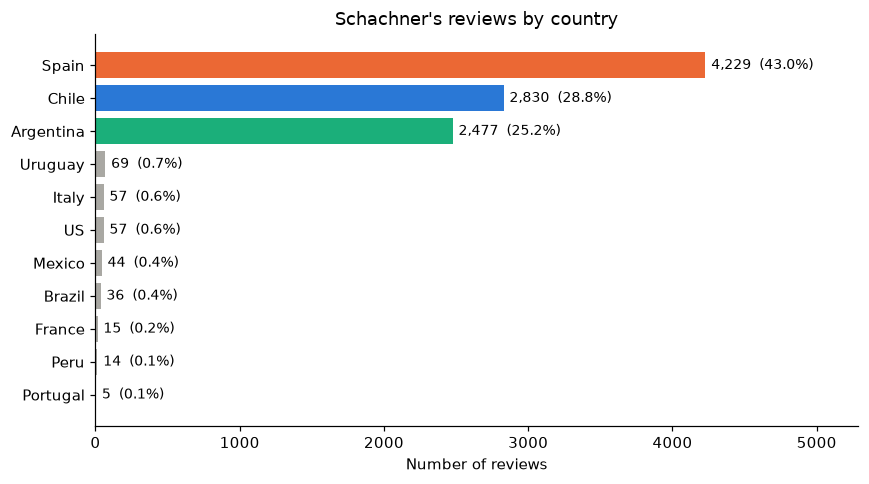

Spain + Chile + Argentina = 97.0% of Schachner's reviews


In [4]:
counts = sch["country"].value_counts()

fig, ax = plt.subplots(figsize=(8, 4.5))
bar_colors = [COLORS.get(c, COLORS["Other"]) for c in counts.index]
ax.barh(counts.index[::-1], counts.values[::-1], color=bar_colors[::-1])
for i, v in enumerate(counts.values[::-1]):
    ax.text(v + 40, i, f"{v:,}  ({v / counts.sum():.1%})", va="center", fontsize=9)
ax.set_xlabel("Number of reviews")
ax.set_title("Schachner's reviews by country")
ax.set_xlim(0, counts.max() * 1.25)
plt.tight_layout()
plt.show()

print(f"Spain + Chile + Argentina = {counts[MAIN].sum() / counts.sum():.1%} of Schachner's reviews")

### How much of each country's coverage is Schachner?
If one taster writes most reviews for a country, a country classifier can just learn that taster's style. This is the confound in one picture.

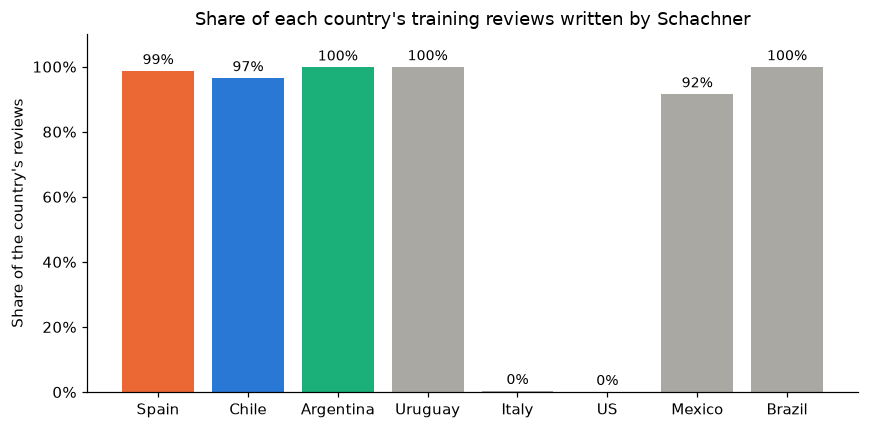

In [5]:
top_countries = counts.index[:8]
share = (train[train["country"].isin(top_countries)]
         .assign(is_sch=lambda d: d["taster_name"] == TASTER)
         .groupby("country")["is_sch"].mean()
         .reindex(top_countries))

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(share.index, share.values, color=[COLORS.get(c, COLORS["Other"]) for c in share.index])
for i, v in enumerate(share.values):
    ax.text(i, v + 0.02, f"{v:.0%}", ha="center", fontsize=9)
ax.yaxis.set_major_formatter(PercentFormatter(1))
ax.set_ylim(0, 1.1)
ax.set_ylabel("Share of the country's reviews")
ax.set_title("Share of each country's training reviews written by Schachner")
plt.tight_layout()
plt.show()

## 3. Scores, prices and review length by country

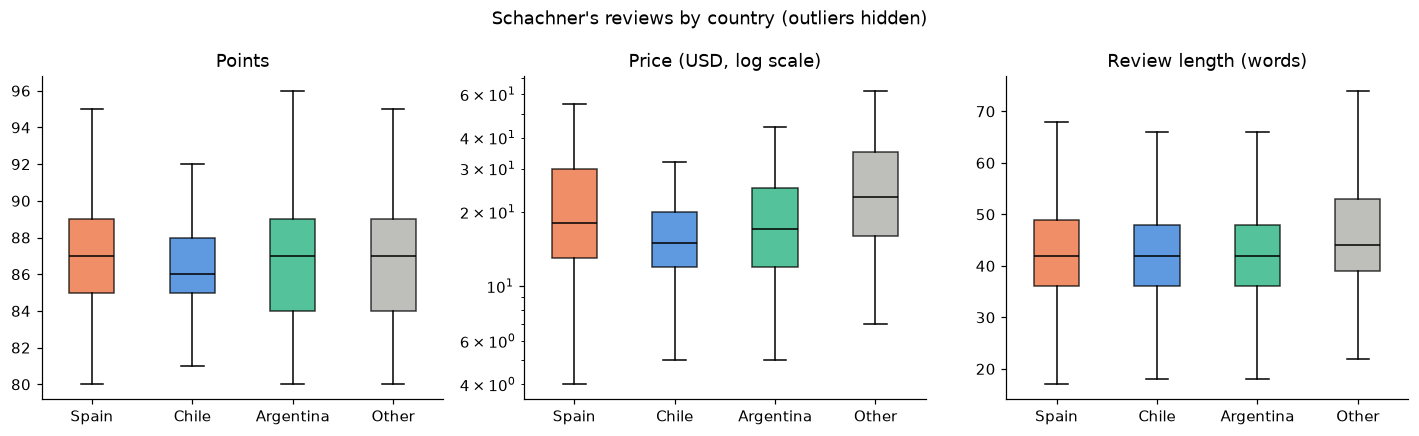

points        price        n_words       
               mean median  mean median    mean median
country_main                                          
Spain          87.3   87.0  28.4   18.0    42.9   42.0
Chile          86.5   86.0  20.7   15.0    42.7   42.0
Argentina      86.7   87.0  24.5   17.0    42.3   42.0
Other          86.4   87.0  29.0   23.0    45.6   44.0

In [6]:
groups = MAIN + ["Other"]
fig, axes = plt.subplots(1, 3, figsize=(13, 4))

for ax, col, title in [
    (axes[0], "points", "Points"),
    (axes[1], "price", "Price (USD, log scale)"),
    (axes[2], "n_words", "Review length (words)"),
]:
    data = [sch.loc[sch["country_main"] == g, col].dropna() for g in groups]
    bp = ax.boxplot(data, tick_labels=groups, patch_artist=True, showfliers=False)
    for patch, g in zip(bp["boxes"], groups):
        patch.set_facecolor(COLORS[g])
        patch.set_alpha(0.75)
    for med in bp["medians"]:
        med.set_color("black")
    ax.set_title(title)

axes[1].set_yscale("log")
fig.suptitle("Schachner's reviews by country (outliers hidden)")
plt.tight_layout()
plt.show()

sch.groupby("country_main")[["points", "price", "n_words"]].agg(["mean", "median"]).round(1).reindex(groups)

### Points vs. price
Does Schachner reward price the same way in each country?

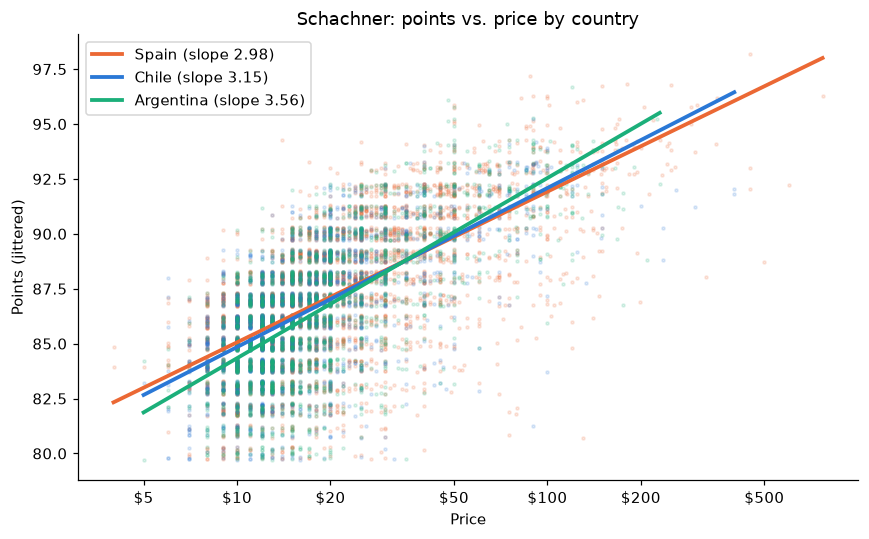

In [7]:
rng = np.random.default_rng(0)
fig, ax = plt.subplots(figsize=(8, 5))
for c in MAIN:
    d = sch[(sch["country"] == c) & sch["price"].notna()]
    ax.scatter(d["log_price"], d["points"] + rng.uniform(-0.3, 0.3, len(d)),
               s=4, alpha=0.15, color=COLORS[c])
    slope, intercept = np.polyfit(d["log_price"], d["points"], 1)
    xs = np.linspace(d["log_price"].min(), d["log_price"].max(), 50)
    ax.plot(xs, slope * xs + intercept, color=COLORS[c], lw=2.5,
            label=f"{c} (slope {slope:.2f})")

ticks = [5, 10, 20, 50, 100, 200, 500]
ax.set_xticks(np.log(ticks), [f"${t}" for t in ticks])
ax.set_xlabel("Price")
ax.set_ylabel("Points (jittered)")
ax.set_title("Schachner: points vs. price by country")
ax.legend()
plt.tight_layout()
plt.show()

## 4. Grape varieties by country
Variety is the main thing mixed up with origin: Malbec says Argentina, Tempranillo says Spain, Carmenère says Chile. The heatmap shows what share of each country's reviews each variety makes up.

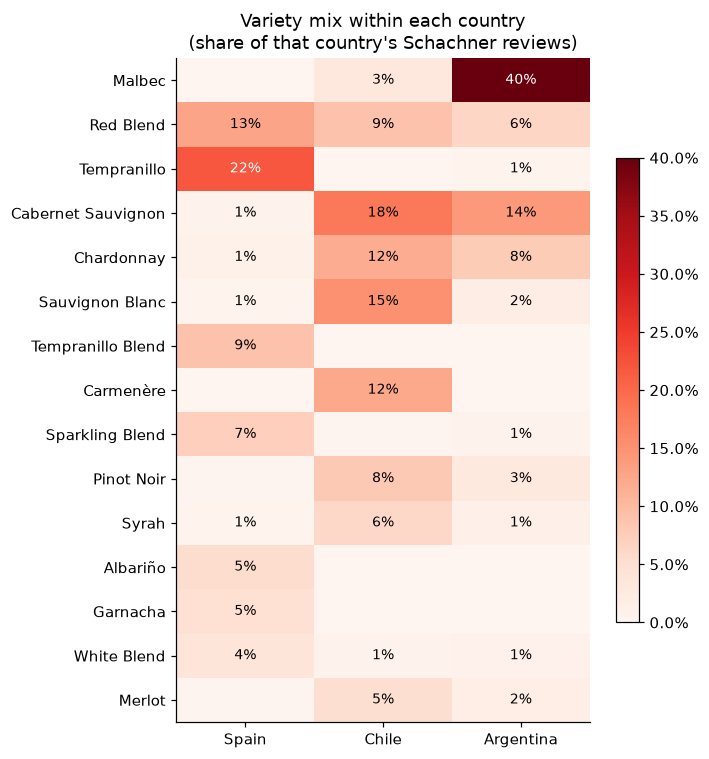

Varieties with >2% share in at least two countries: ['Malbec', 'Red Blend', 'Cabernet Sauvignon', 'Chardonnay', 'Pinot Noir']


In [8]:
main = sch[sch["country"].isin(MAIN)].reset_index(drop=True)
top_var = main["variety"].value_counts().index[:15]
var_mix = pd.crosstab(main["variety"], main["country"], normalize="columns").reindex(top_var)[MAIN]

fig, ax = plt.subplots(figsize=(6.5, 7))
im = ax.imshow(var_mix.values, cmap="Reds", aspect="auto")
ax.set_xticks(range(len(MAIN)), MAIN)
ax.set_yticks(range(len(top_var)), top_var)
for i in range(var_mix.shape[0]):
    for j in range(var_mix.shape[1]):
        v = var_mix.values[i, j]
        if v >= 0.005:
            ax.text(j, i, f"{v:.0%}", ha="center", va="center",
                    color="white" if v > 0.2 else "black", fontsize=9)
ax.set_title("Variety mix within each country\n(share of that country's Schachner reviews)")
plt.colorbar(im, ax=ax, format=PercentFormatter(1), shrink=0.7)
plt.tight_layout()
plt.show()

shared = var_mix[(var_mix > 0.02).sum(axis=1) >= 2].index.tolist()
print("Varieties with >2% share in at least two countries:", shared)

## 5. Words that set each country apart
Log-odds ratio with an informative prior (Monroe et al., 2008): how much more often Schachner uses a word for one country than for the other two. Positive means the word leans toward that country.

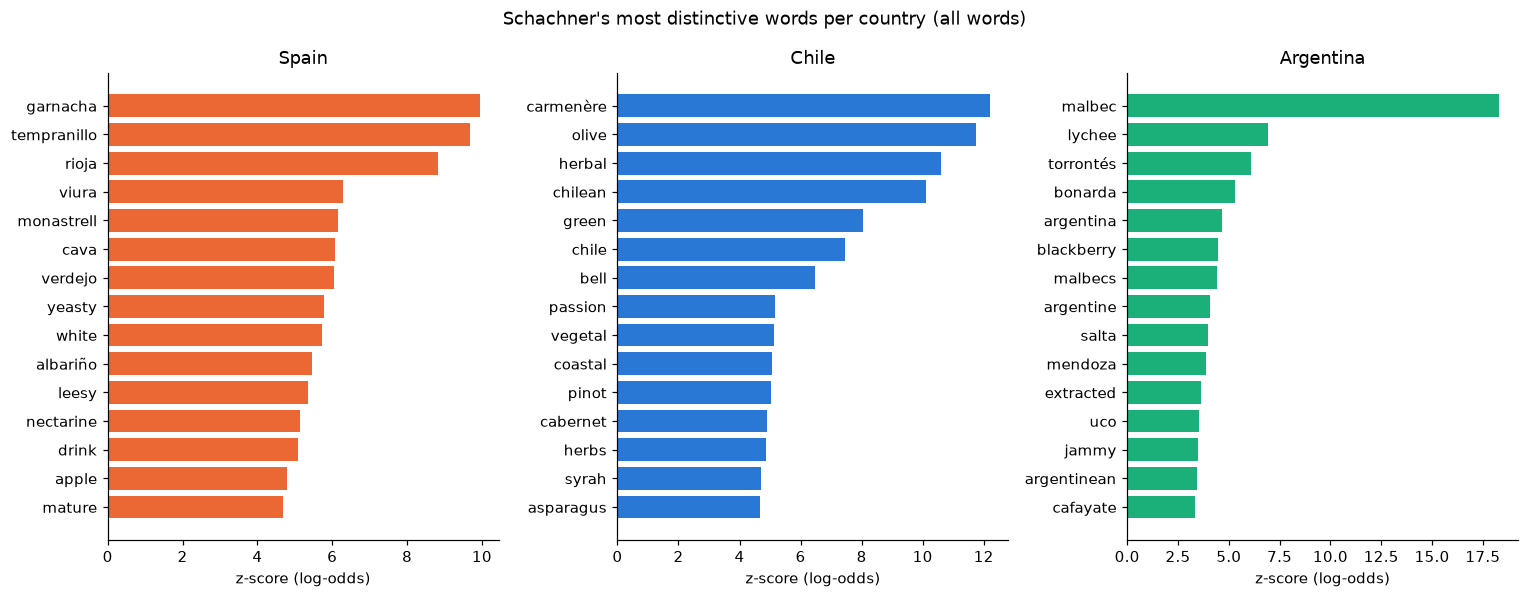

In [9]:
def log_odds_z(texts, mask, min_df=10):
    """z-scored log-odds of each word: reviews where mask is True vs. the rest."""
    cv = CountVectorizer(min_df=min_df, token_pattern=TOKEN)
    X = cv.fit_transform(texts.str.lower())
    prior = np.asarray(X.sum(axis=0)).ravel() + 0.01
    a0 = prior.sum()
    y_i = np.asarray(X[mask].sum(axis=0)).ravel()
    y_j = np.asarray(X[~mask].sum(axis=0)).ravel()
    d = (np.log((y_i + prior) / (y_i.sum() + a0 - y_i - prior))
         - np.log((y_j + prior) / (y_j.sum() + a0 - y_j - prior)))
    return pd.Series(d / np.sqrt(1 / (y_i + prior) + 1 / (y_j + prior)), index=cv.get_feature_names_out())


z = {c: log_odds_z(main["description"], (main["country"] == c).values) for c in MAIN}


def plot_top_words(zdict, title, n=15):
    fig, axes = plt.subplots(1, 3, figsize=(14, 5.5))
    for ax, c in zip(axes, MAIN):
        top = zdict[c].nlargest(n)[::-1]
        ax.barh(top.index, top.values, color=COLORS[c])
        ax.set_title(c)
        ax.set_xlabel("z-score (log-odds)")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()


plot_top_words(z, "Schachner's most distinctive words per country (all words)")

### Same thing, with place names and grape varieties removed
Words like *malbec* or *rioja* name the answer outright. Removing them shows whether Schachner describes the wines themselves differently by country.

In [10]:
# Words taken from the grape and place columns.
# (winery / designation are left out on purpose: they contain ordinary words like "oak" or "green".)
name_tokens = set()
for col in ["variety", "province", "region_1", "region_2", "country"]:
    for val in sch[col].dropna().unique():
        name_tokens.update(re.findall(r"[^\W\d_]{3,}", val.lower()))

# Ordinary words that happen to appear in those columns: keep them as descriptive words
name_tokens -= {"and", "other", "red", "white", "style", "sparkling", "blend", "northern"}

# Plurals, nicknames, nationality words and label terms that point straight at a country
name_tokens |= {"malbecs", "cab", "cabs", "carmenere", "carmenères", "torrontes", "tempranillos",
                "chardonnays", "spanish", "chilean", "argentine", "argentinean", "argentinian",
                "andes", "uco", "colchagua", "crianza", "reserva", "gran"}

print(sorted(name_tokens & set(z[MAIN[0]].index)))

['albariño', 'alta', 'argentina', 'argentine', 'argentinean', 'blanc', 'blanca', 'blanco', 'bobal', 'bonarda', 'bordeaux', 'cab', 'cabernet', 'cafayate', 'carignan', 'carmenère', 'casablanca', 'cava', 'central', 'chardonnay', 'chile', 'chilean', 'crianza', 'del', 'duero', 'elqui', 'fino', 'franc', 'garnacha', 'godello', 'graciano', 'gran', 'grenache', 'leyda', 'macabeo', 'maipo', 'malbec', 'malbecs', 'malvasia', 'maule', 'mencía', 'mendoza', 'merlot', 'monastrell', 'moscatel', 'mourvèdre', 'navarra', 'noir', 'pedro', 'petit', 'picudo', 'pinot', 'prieto', 'priorat', 'reserva', 'ribera', 'riesling', 'rioja', 'rosado', 'rosé', 'rueda', 'salta', 'san', 'santa', 'sauvignon', 'sherry', 'shiraz', 'spain', 'spanish', 'syrah', 'tannat', 'tempranillo', 'tinto', 'toro', 'torrontés', 'treixadura', 'trepat', 'uco', 'valencia', 'valley', 'verdejo', 'verdot', 'viognier', 'viura']


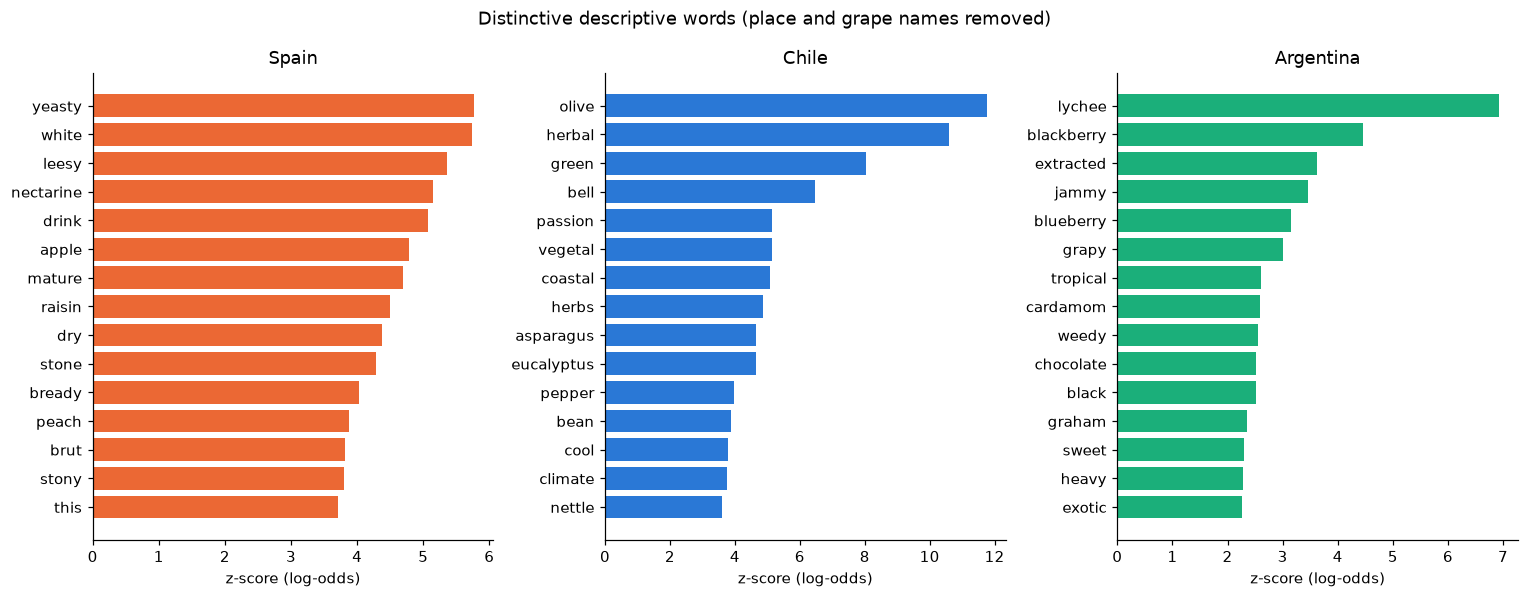

Removed 84 of 2,049 vocabulary words as names


In [11]:


z_clean = {c: s[~s.index.isin(name_tokens)] for c, s in z.items()}
plot_top_words(z_clean, "Distinctive descriptive words (place and grape names removed)")

vocab = z[MAIN[0]].index
print(f"Removed {vocab.isin(list(name_tokens)).sum():,} of {len(vocab):,} vocabulary words as names")

## 6. Same grape, different country
Holding **both** the taster and the grape fixed is the cleanest look at origin. If Schachner still writes differently about Chilean and Argentine Cabernet, that's origin signal.

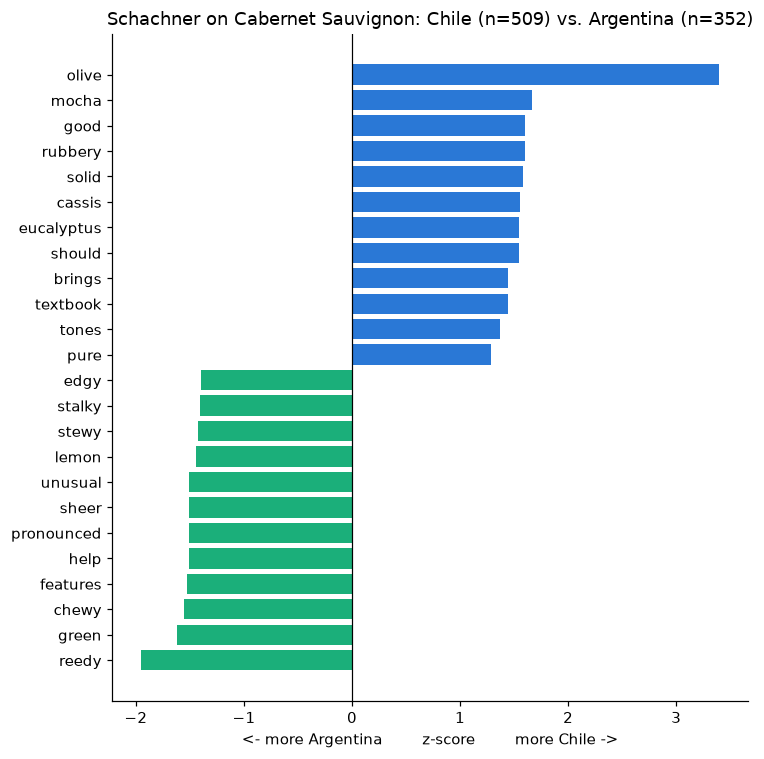

In [12]:
def compare_variety(variety, c1, c2, n=12):
    d = main[(main["variety"] == variety) & main["country"].isin([c1, c2])].reset_index(drop=True)
    m = (d["country"] == c1).values
    zz = log_odds_z(d["description"], m, min_df=5)
    zz = zz[~zz.index.isin(name_tokens)]
    sel = pd.concat([zz.nsmallest(n), zz.nlargest(n)[::-1]])

    fig, ax = plt.subplots(figsize=(7, 7))
    ax.barh(sel.index, sel.values, color=[COLORS[c1] if v > 0 else COLORS[c2] for v in sel.values])
    ax.axvline(0, color="black", lw=0.8)
    ax.set_xlabel(f"<- more {c2}        z-score        more {c1} ->")
    ax.set_title(f"Schachner on {variety}: {c1} (n={m.sum()}) vs. {c2} (n={(~m).sum()})")
    plt.tight_layout()
    plt.show()


compare_variety("Cabernet Sauvignon", "Chile", "Argentina")

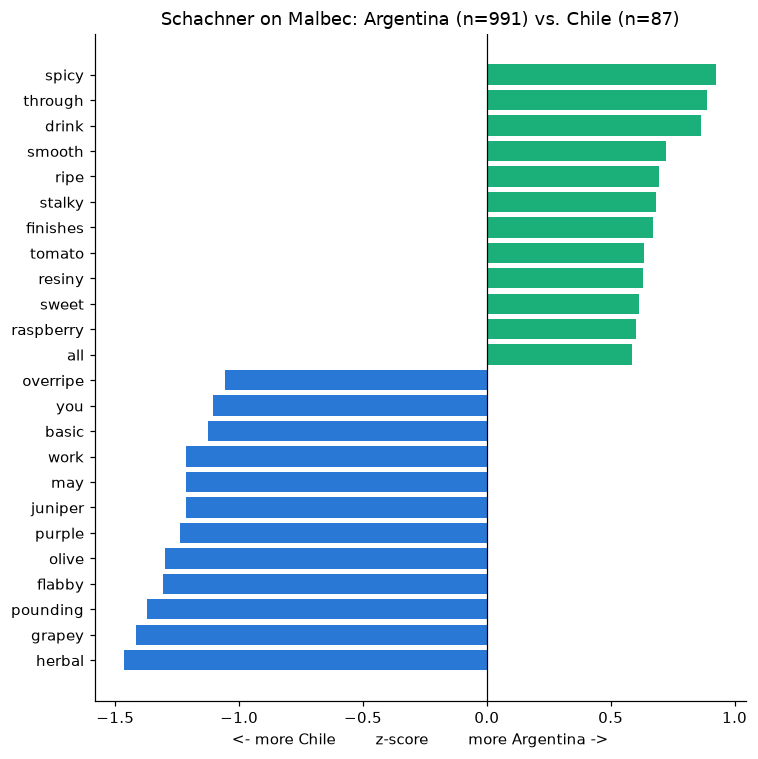

In [13]:
compare_variety("Malbec", "Argentina", "Chile")

## 7. Can a model tell the countries apart within Schachner's reviews?
A quick check using an 80/20 split *inside* Schachner's training reviews, with the same setup as the bias-variance model (logistic regression, TF-IDF, C=10, balanced classes). Run once with all words and once with place and grape names removed.

In [14]:
tr, te = train_test_split(main, test_size=0.2, stratify=main["country"], random_state=42)


def fit_eval(drop_words=None):
    vec = TfidfVectorizer(max_features=10_000, sublinear_tf=True, stop_words=drop_words,
                          token_pattern=TOKEN)
    Xtr = vec.fit_transform(tr["description"].str.lower())
    Xte = vec.transform(te["description"].str.lower())
    clf = LogisticRegression(C=10, class_weight="balanced", max_iter=2000)
    clf.fit(Xtr, tr["country"])
    pred = clf.predict(Xte)
    return pred, accuracy_score(te["country"], pred), f1_score(te["country"], pred, average="macro")


pred_all, acc_all, f1_all = fit_eval()
pred_clean, acc_clean, f1_clean = fit_eval(drop_words=sorted(name_tokens))
majority = te["country"].value_counts(normalize=True).iloc[0]

results = pd.DataFrame({
    "accuracy": [majority, acc_all, acc_clean],
    "macro F1": [np.nan, f1_all, f1_clean],
}, index=["Always guess Spain", "All words", "Names removed"]).round(3)
results

,accuracy,macro F1
Always guess Spain,0.443,NaN
All words,0.649,0.633
Names removed,0.534,0.521


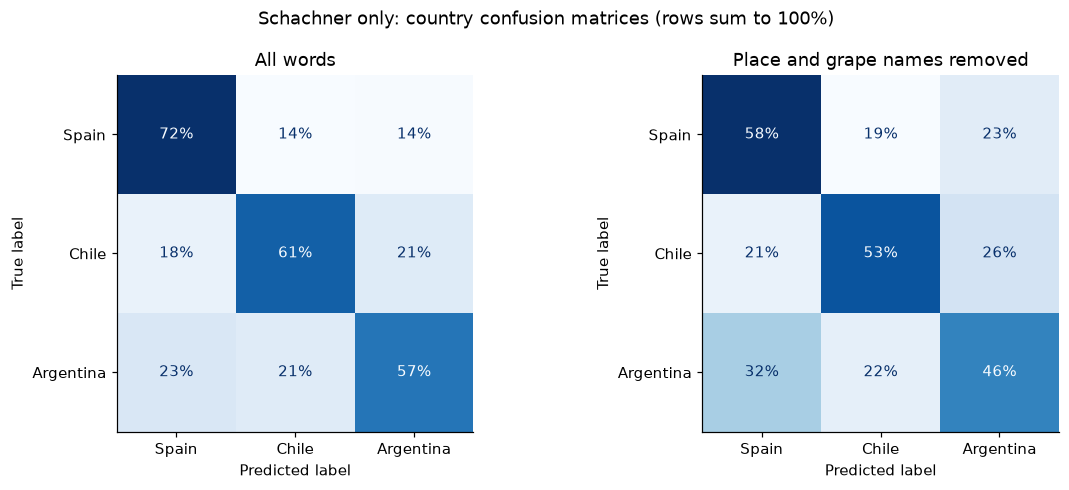

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, pred, title in [(axes[0], pred_all, "All words"),
                        (axes[1], pred_clean, "Place and grape names removed")]:
    ConfusionMatrixDisplay.from_predictions(te["country"], pred, labels=MAIN, normalize="true",
                                            values_format=".0%", cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(title)
fig.suptitle("Schachner only: country confusion matrices (rows sum to 100%)")
plt.tight_layout()
plt.show()

# Part 2: Models and slide-ready figures

This part follows the same setup as the Voss and Krebiehl notebooks (most-frequent dummy, logistic regression, decision tree, same TF-IDF settings). It adds the **general model trained on every taster**, as in the Iijima notebook.

- Data: the team's **shared train / val / test splits**, filtered to Schachner. Models are compared on validation; the test set is scored once at the end.
- Slide figures are saved as 16:9 PNGs in `figures/schachner/`.

## 8. Slide setup

In [16]:
from pathlib import Path

from joblib import parallel_config
from sklearn.dummy import DummyClassifier
from sklearn.metrics import confusion_matrix
from sklearn.multiclass import OneVsRestClassifier

SEED = 42
TARGETS = ["country", "province", "region_1"]
MIN_TRAIN_REVIEWS = 20         # same as the Iijima notebook; drops classes too small to learn
GLOBAL_MIN_TRAIN_REVIEWS = 70  # rule used by the general model in tfidf_baselines
N_JOBS = -1

FIG_DIR = Path("figures/schachner")
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Slide palette: text stays in ink colors; one blue highlight; everything else neutral gray
INK, INK_2, INK_3 = "#0b0b0b", "#52514e", "#8a8984"
GRID = "#e5e4df"
HILITE, HILITE_LIGHT, NEUTRAL = "#2a78d6", "#8fb6e8", "#c9c8c3"

SLIDE_RC = {
    "figure.figsize": (13.33, 7.5),   # 16:9
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "font.size": 15,
    "axes.titlesize": 17,
    "axes.titleweight": "bold",
    "axes.titlelocation": "left",
    "axes.titlepad": 12,
    "axes.labelsize": 14,
    "axes.labelcolor": INK_2,
    "axes.edgecolor": INK_3,
    "xtick.color": INK_2,
    "ytick.color": INK,
    "xtick.labelsize": 13,
    "ytick.labelsize": 14,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": False,
    "text.color": INK,
}


def slide_title(fig, title, subtitle=None):
    fig.suptitle(title, x=0.01, y=0.99, ha="left", va="top", fontsize=24, fontweight="bold", color=INK)
    if subtitle:
        fig.text(0.01, 0.915, subtitle, ha="left", va="top", fontsize=15, color=INK_2)


def save_slide(fig, name):
    path = FIG_DIR / f"{name}.png"
    fig.savefig(path, dpi=200, bbox_inches="tight", facecolor="white")
    print(f"saved {path}")


def hbar(ax, labels, values, colors, fmt="{:.0%}", xmax=None):
    """Horizontal bars, first item on top, value printed at the end of each bar."""
    y = np.arange(len(labels))[::-1]
    ax.barh(y, values, color=colors, height=0.62)
    xmax = xmax or max(values) * 1.18
    for yi, v in zip(y, values):
        ax.text(v + xmax * 0.012, yi, fmt.format(v), va="center", fontsize=14, color=INK)
    ax.set_yticks(y, labels)
    ax.set_xlim(0, xmax)
    ax.tick_params(axis="y", length=0)
    ax.spines["left"].set_visible(False)
    ax.xaxis.set_visible(False)
    ax.spines["bottom"].set_visible(False)

## 9. Slide figures: who is Schachner?

### Slide A: Schachner covers Spain, Chile and Argentina almost alone

saved figures/schachner/A_who_schachner_covers.png


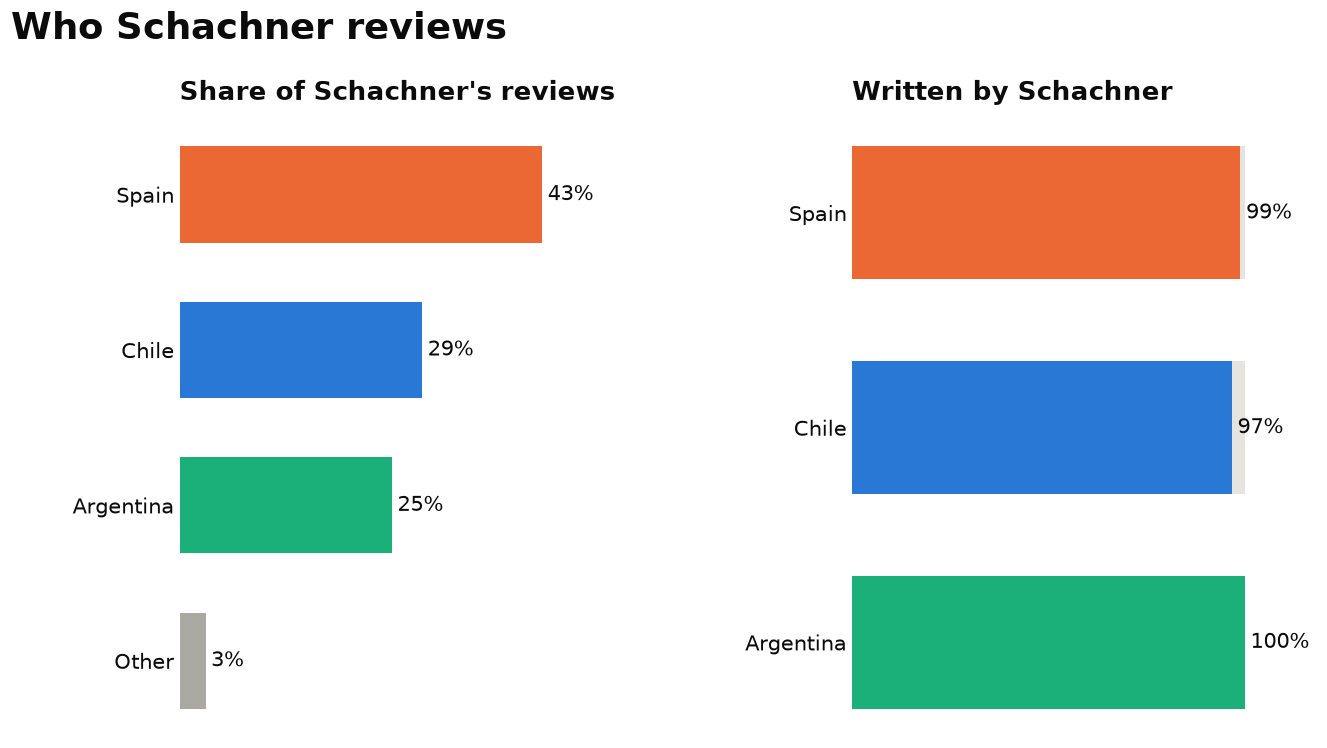

In [17]:
by_country = sch["country_main"].value_counts().reindex(MAIN + ["Other"])
n_other = sch.loc[sch["country_main"] == "Other", "country"].nunique()
coverage = (train[train["country"].isin(MAIN)]
            .assign(is_sch=lambda d: d["taster_name"] == TASTER)
            .groupby("country")["is_sch"].mean().reindex(MAIN))

with plt.rc_context(SLIDE_RC):
    fig, (ax1, ax2) = plt.subplots(1, 2, gridspec_kw={"wspace": 0.45})

    labels = MAIN + ["Other"]
    share = by_country / by_country.sum()
    hbar(ax1, labels, share.values, [COLORS[c] for c in MAIN + ["Other"]], xmax=0.55)
    ax1.set_title("Share of Schachner's reviews")

    ax2.barh(np.arange(3)[::-1], [1] * 3, color=GRID, height=0.62)          # 100% track
    hbar(ax2, MAIN, coverage.values, [COLORS[c] for c in MAIN], xmax=1.18)
    ax2.set_title("Written by Schachner")

    slide_title(fig, "Who Schachner reviews")
    fig.subplots_adjust(top=0.86)
    save_slide(fig, "A_who_schachner_covers")
    plt.show()

### Slide B: a high-volume reviewer of everyday wines

saved figures/schachner/B_what_kind_of_reviewer.png


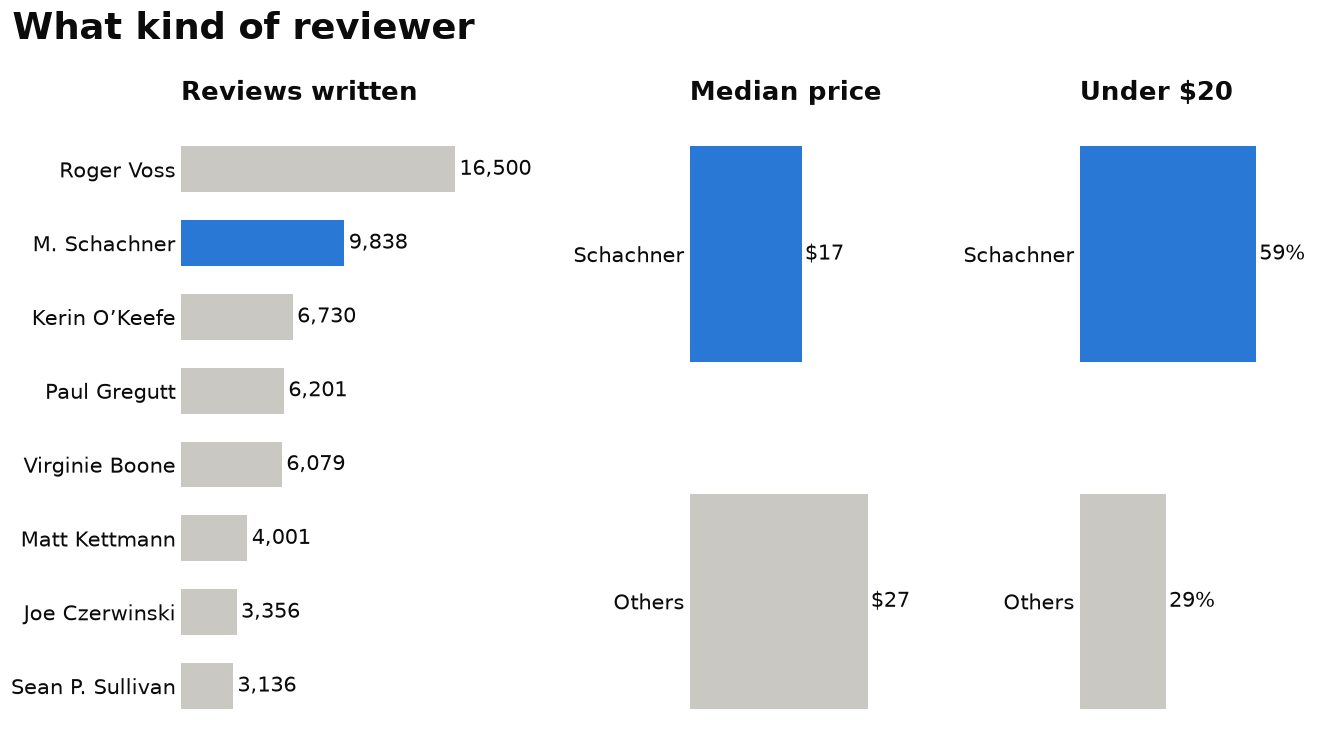

In [18]:
known = train[train["taster_name"].notna()].copy()
known["is_sch"] = known["taster_name"] == TASTER
volume = known["taster_name"].value_counts().head(8)
rank = known["taster_name"].value_counts().index.get_loc(TASTER) + 1
n_tasters = known["taster_name"].nunique()

med_price = known.groupby("is_sch")["price"].median()
under_20 = known[known["price"].notna()].assign(cheap=lambda d: d["price"] < 20).groupby("is_sch")["cheap"].mean()
med_pts = known.groupby("is_sch")["points"].median()

with plt.rc_context(SLIDE_RC):
    fig, axes = plt.subplots(1, 3, gridspec_kw={"width_ratios": [1.5, 1, 1], "wspace": 0.55})

    short = [n.replace("Michael ", "M. ") for n in volume.index]
    hbar(axes[0], short, volume.values,
         [HILITE if n == TASTER else NEUTRAL for n in volume.index], fmt="{:,.0f}", xmax=volume.max() * 1.3)
    axes[0].set_title("Reviews written")

    pair = ["Schachner", "Others"]
    hbar(axes[1], pair, [med_price[True], med_price[False]], [HILITE, NEUTRAL], fmt="${:.0f}", xmax=36)
    axes[1].set_title("Median price")

    hbar(axes[2], pair, [under_20[True], under_20[False]], [HILITE, NEUTRAL], xmax=0.8)
    axes[2].set_title("Under $20")

    slide_title(fig, "What kind of reviewer")
    fig.subplots_adjust(top=0.86)
    save_slide(fig, "B_what_kind_of_reviewer")
    plt.show()

## 10. Models: dummy vs. decision tree vs. logistic regression vs. general model

Same settings as the Voss notebook so results line up:
- **Most frequent (dummy):** always predicts Schachner's most common training label.
- **Decision tree:** `max_depth=30`, `min_samples_leaf=5`.
- **Logistic regression (Schachner only):** one-vs-rest, `C=10`, TF-IDF on 1-2 word phrases (20k max).
- **General model (all tasters):** the same logistic regression trained on **every** taster's training reviews (classes with at least 70 reviews), then scored on Schachner's reviews. This is the team baseline from `tfidf_baselines.ipynb`.
- **Schachner LR, names removed** (country only): the Schachner model with the place and grape names from section 5 removed.

In [19]:
splits = {name: pd.read_parquet(f"data_clean/splits/{name}.parquet") for name in ["train", "val", "test"]}
s_train, s_val, s_test = (splits[n][splits[n]["taster_name"] == TASTER].reset_index(drop=True)
                          for n in ["train", "val", "test"])
print(f"Schachner reviews - train {len(s_train):,}, validation {len(s_val):,}, test {len(s_test):,}")

TFIDF = dict(ngram_range=(1, 2), min_df=5, max_df=0.9, sublinear_tf=True, max_features=20000)
vectorizer = TfidfVectorizer(**TFIDF)
X_train = vectorizer.fit_transform(s_train["description"])
X_val, X_test = vectorizer.transform(s_val["description"]), vectorizer.transform(s_test["description"])

keep, summary = {}, []
for target in TARGETS:
    counts = s_train[target].value_counts()
    keep[target] = counts[counts >= MIN_TRAIN_REVIEWS].index
    summary.append({"target": target, "all_classes": s_train[target].nunique(), "kept_classes": len(keep[target]),
                    "pct_missing": s_train[target].isna().mean() * 100,
                    "pct_rows_kept": s_train[target].isin(keep[target]).mean() * 100})
pd.DataFrame(summary).set_index("target").round(1)

Schachner reviews - train 9,838, validation 2,098, test 2,108


,all_classes,kept_classes,pct_missing,pct_rows_kept
target,,,,
country,11,8,0.1,99.6
province,80,29,0.1,97.0
region_1,140,45,30.9,64.1


In [20]:
def subset(split, X, target):
    mask = split[target].isin(keep[target]).to_numpy()
    return X[mask], split[target].to_numpy()[mask], mask


def make_models():
    return {
        "Most frequent (dummy)": DummyClassifier(strategy="most_frequent"),
        "Decision tree": DecisionTreeClassifier(max_depth=30, min_samples_leaf=5, random_state=SEED),
        "Logistic regression (Schachner only)": OneVsRestClassifier(
            LogisticRegression(C=10, solver="liblinear")),   # small data: no parallel workers needed
    }


fitted = {}
for target in TARGETS:
    Xt, yt, _ = subset(s_train, X_train, target)
    for name, model in make_models().items():
        with parallel_config(max_nbytes=None):
            fitted[target, name] = model.fit(Xt, yt)

# Schachner LR with place / grape names removed (country only)
clean_vectorizer = TfidfVectorizer(**TFIDF, stop_words=sorted(name_tokens))
Xc_train = clean_vectorizer.fit_transform(s_train["description"])
Xt, yt, _ = subset(s_train, Xc_train, "country")
fitted["country", "Logistic regression, names removed"] = OneVsRestClassifier(
    LogisticRegression(C=10, solver="liblinear")).fit(Xt, yt)
print("Schachner models fitted")

Schachner models fitted


In [21]:
# General model: trained on every taster's training reviews (team baseline)
full_train = splits["train"]
global_vectorizer = TfidfVectorizer(**TFIDF)
X_full = global_vectorizer.fit_transform(full_train["description"])
for target in TARGETS:
    counts = full_train[target].value_counts()
    mask = full_train[target].isin(counts[counts >= GLOBAL_MIN_TRAIN_REVIEWS].index).to_numpy()
    model = OneVsRestClassifier(LogisticRegression(C=10, solver="liblinear"), n_jobs=N_JOBS)
    with parallel_config(max_nbytes=None):
        fitted[target, "General model (all tasters)"] = model.fit(X_full[mask], full_train[target].to_numpy()[mask])
print("General models fitted")

General models fitted


In [22]:
MODEL_ORDER = ["Most frequent (dummy)", "Decision tree", "General model (all tasters)",
               "Logistic regression (Schachner only)", "Logistic regression, names removed"]


def evaluate(split, split_name):
    X_s = vectorizer.transform(split["description"])
    X_g = global_vectorizer.transform(split["description"])
    X_c = clean_vectorizer.transform(split["description"])
    rows, preds = [], {}
    for target in TARGETS:
        mask = split[target].isin(keep[target]).to_numpy()
        y = split[target].to_numpy()[mask]
        for name in MODEL_ORDER:
            if (target, name) not in fitted:
                continue
            X = {"General model (all tasters)": X_g, "Logistic regression, names removed": X_c}.get(name, X_s)
            pred = fitted[target, name].predict(X[mask])
            preds[target, name] = (y, pred)
            rows.append({"split": split_name, "target": target, "model": name,
                         "accuracy": accuracy_score(y, pred),
                         "macro_F1": f1_score(y, pred, labels=keep[target], average="macro", zero_division=0)})
    return pd.DataFrame(rows).set_index(["target", "model"]), preds


# Training accuracy shows overfitting, as in the Voss notebook
train_acc = {}
for (target, name), model in fitted.items():
    if name in ("General model (all tasters)", "Logistic regression, names removed"):
        continue
    Xt, yt, _ = subset(s_train, X_train, target)
    with parallel_config(max_nbytes=None):
        train_acc[target, name] = accuracy_score(yt, model.predict(Xt))

with parallel_config(max_nbytes=None):
    val_results, val_preds = evaluate(s_val, "validation")
val_results.insert(0, "train_accuracy", pd.Series(train_acc))
val_results.drop(columns="split").round(3)

train_accuracy  accuracy  \
target   model                                                            
country  Most frequent (dummy)                          0.432     0.433   
         Decision tree                                  0.696     0.591   
         General model (all tasters)                      NaN     0.592   
         Logistic regression (Schachner only)           0.986     0.622   
         Logistic regression, names removed               NaN     0.518   
province Most frequent (dummy)                          0.260     0.243   
         Decision tree                                  0.495     0.355   
         General model (all tasters)                      NaN     0.378   
         Logistic regression (Schachner only)           0.994     0.423   
region_1 Most frequent (dummy)                          0.240     0.230   
         Decision tree                                  0.505     0.351   
         General model (all tasters)                      NaN     0.390   
         Logistic regression (Schachner only)           0.999     0.385   

                                               macro_F1  
target   model                                           
country  Most frequent (dummy)                    0.076  
         Decision tree                            0.373  
         General model (all tasters)              0.242  
         Logistic regression (Schachner only)     0.273  
         Logistic regression, names removed       0.183  
province Most frequent (dummy)                    0.013  
         Decision tree                            0.148  
         General model (all tasters)              0.155  
         Logistic regression (Schachner only)     0.178  
region_1 Most frequent (dummy)                    0.008  
         Decision tree                            0.143  
         General model (all tasters)              0.121  
         Logistic regression (Schachner only)     0.122

### Validation results

Read across a row: a useful model beats the dummy on both accuracy and macro F1. A big gap between training and validation accuracy means overfitting.

## 11. Final test results (scored once)

In [23]:
with parallel_config(max_nbytes=None):
    test_results, test_preds = evaluate(s_test, "test")
test_results.drop(columns="split").round(3)

accuracy  macro_F1
target   model                                                   
country  Most frequent (dummy)                    0.434     0.076
         Decision tree                            0.576     0.301
         General model (all tasters)              0.594     0.246
         Logistic regression (Schachner only)     0.629     0.258
         Logistic regression, names removed       0.537     0.191
province Most frequent (dummy)                    0.271     0.015
         Decision tree                            0.361     0.166
         General model (all tasters)              0.406     0.160
         Logistic regression (Schachner only)     0.448     0.175
region_1 Most frequent (dummy)                    0.242     0.009
         Decision tree                            0.364     0.165
         General model (all tasters)              0.409     0.138
         Logistic regression (Schachner only)     0.427     0.152

In [24]:
# Gain over the dummy, in percentage points of accuracy
gain = (test_results["accuracy"].unstack("model").sub(
    test_results["accuracy"].unstack("model")["Most frequent (dummy)"], axis=0) * 100)
gain = gain[[m for m in MODEL_ORDER if m in gain.columns]].round(1)
gain

model,Most frequent (dummy),Decision tree,General model (all tasters),Logistic regression (Schachner only),"Logistic regression, names removed"
target,,,,,
country,0.0,14.2,16.0,19.5,10.4
province,0.0,9.0,13.5,17.7,NaN
region_1,0.0,12.2,16.7,18.6,NaN


## 12. Slide figures: model results

### Country model compared with the baselines
_Original (untuned) Schachner model. The slide version with the tuned model is in section 19._

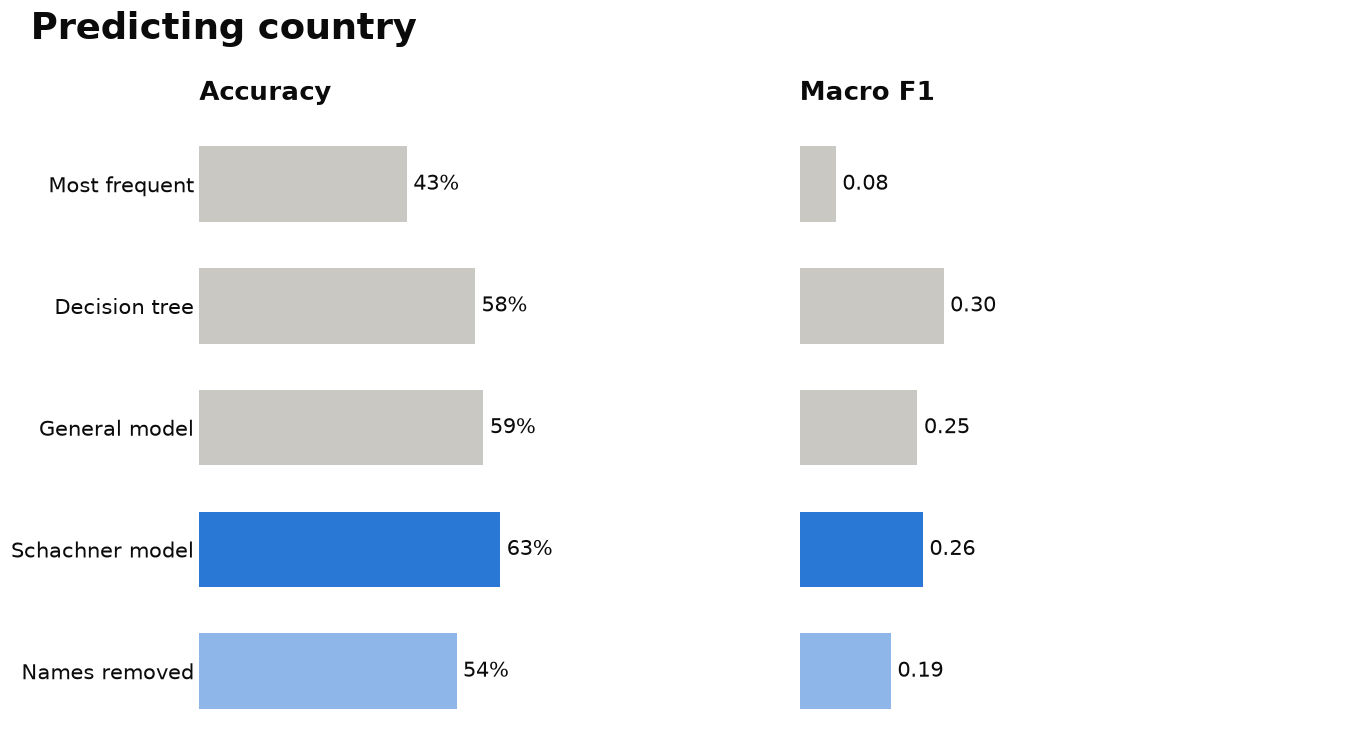

In [25]:
SHORT = {
    "Most frequent (dummy)": "Most frequent",
    "Decision tree": "Decision tree",
    "General model (all tasters)": "General model",
    "Logistic regression (Schachner only)": "Schachner model",
    "Logistic regression, names removed": "Names removed",
}
SLIDE_COLORS = {
    "Most frequent (dummy)": NEUTRAL, "Decision tree": NEUTRAL, "General model (all tasters)": NEUTRAL,
    "Logistic regression (Schachner only)": HILITE, "Logistic regression, names removed": HILITE_LIGHT,
}

country = test_results.loc["country"].reindex(MODEL_ORDER)
sch_acc = country.loc["Logistic regression (Schachner only)", "accuracy"]
gen_acc = country.loc["General model (all tasters)", "accuracy"]
dum_acc = country.loc["Most frequent (dummy)", "accuracy"]

with plt.rc_context(SLIDE_RC):
    fig, (ax1, ax2) = plt.subplots(1, 2, sharey=True, gridspec_kw={"wspace": 0.12})
    labels = [SHORT[m] for m in MODEL_ORDER]
    colors = [SLIDE_COLORS[m] for m in MODEL_ORDER]
    hbar(ax1, labels, country["accuracy"].values, colors, xmax=1.12)
    ax1.set_title("Accuracy")
    hbar(ax2, labels, country["macro_F1"].values, colors, fmt="{:.2f}", xmax=1.12)
    ax2.set_title("Macro F1")
    ax2.tick_params(axis="y", labelleft=False)

    verb = "beats" if sch_acc > gen_acc else "trails"
    slide_title(fig, "Predicting country")
    fig.subplots_adjust(top=0.86)
    plt.show()

### Slide D: country, province and region side by side

saved figures/schachner/D_all_targets.png


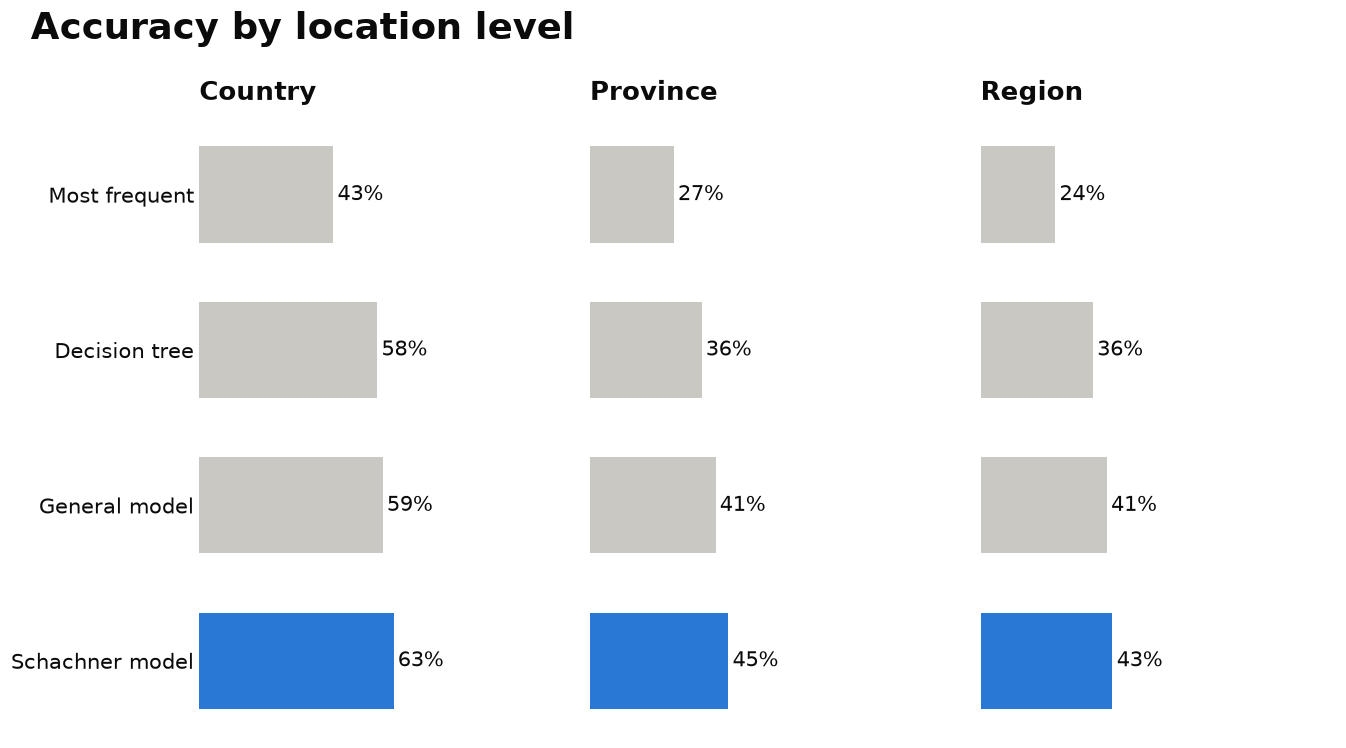

In [26]:
TARGET_TITLES = {"country": "Country", "province": "Province", "region_1": "Region"}
CORE = ["Most frequent (dummy)", "Decision tree", "General model (all tasters)", "Logistic regression (Schachner only)"]

with plt.rc_context(SLIDE_RC):
    fig, axes = plt.subplots(1, 3, sharey=True, gridspec_kw={"wspace": 0.1})
    for ax, target in zip(axes, TARGETS):
        r = test_results.loc[target].reindex(CORE)
        hbar(ax, [SHORT[m] for m in CORE], r["accuracy"].values, [SLIDE_COLORS[m] for m in CORE], xmax=1.15)
        ax.set_title(TARGET_TITLES[target])
        if ax is not axes[0]:
            ax.tick_params(axis="y", labelleft=False)

    slide_title(fig, "Accuracy by location level")
    fig.subplots_adjust(top=0.86)
    save_slide(fig, "D_all_targets")
    plt.show()

### Where the Schachner model goes wrong
_Original (untuned) Schachner model. The slide version with the tuned model is in section 19._

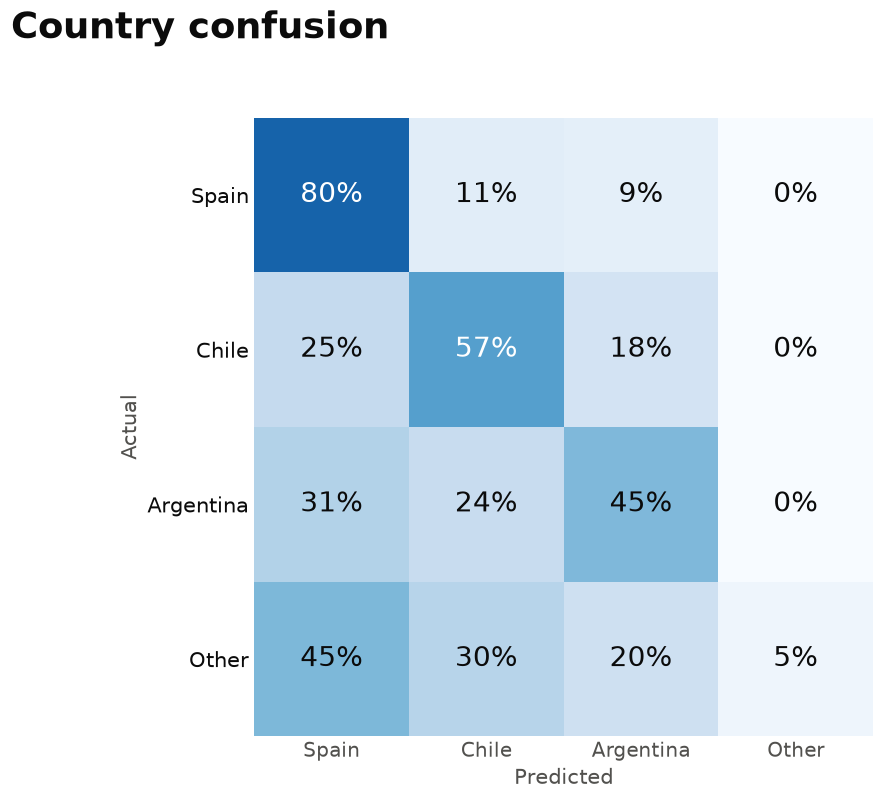

In [27]:
y, pred = test_preds["country", "Logistic regression (Schachner only)"]
group = lambda a: np.where(np.isin(a, MAIN), a, "Other")
labels = MAIN + ["Other"]
cm = confusion_matrix(group(y), group(pred), labels=labels)
share = cm / cm.sum(axis=1, keepdims=True)

with plt.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(10, 7.5))
    ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
    for i, j in np.ndindex(cm.shape):
        ax.text(j, i, f"{share[i, j]:.0%}", ha="center", va="center", fontsize=18,
                color="white" if share[i, j] > 0.55 else INK)
    ax.set_xticks(range(4), labels)
    ax.set_yticks(range(4), labels)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)

    recall = pd.Series(np.diag(share), index=labels)
    easiest = recall[MAIN].idxmax()
    off = pd.DataFrame(share, index=labels, columns=labels).loc[MAIN, MAIN]
    off = off.where(~np.eye(3, dtype=bool)).stack()
    (true_c, pred_c), off_share = off.idxmax(), off.max()
    slide_title(fig, "Country confusion")
    fig.subplots_adjust(top=0.86)
    plt.show()

# Part 3: Bias-variance: fixing the overfitting

The Voss-style logistic regression in Part 2 is about **99% accurate on training data but about 62% on validation**: high variance. Following the assignment's approach, we start from that overfit model and pull each lever in turn:

1. **Add data:** learning curves over training-set size.
2. **Regularize:** sweep `C` (smaller `C` = stronger penalty) and class weights.
3. **Reduce capacity:** fewer / simpler features (single words vs. 1-2 word phrases, vocabulary size).
4. **Add data from other tasters:** does borrowing other reviewers' data help?

All choices are made on **validation**. The test set is used once, at the end. Target: country.

In [28]:
tr_mask = s_train["country"].isin(keep["country"]).to_numpy()
va_mask = s_val["country"].isin(keep["country"]).to_numpy()
te_mask = s_test["country"].isin(keep["country"]).to_numpy()
cv_train = s_train[tr_mask].reset_index(drop=True)
cv_val = s_val[va_mask].reset_index(drop=True)
cv_test = s_test[te_mask].reset_index(drop=True)

OVERFIT = dict(ngram_range=(1, 2), max_features=20000, min_df=5, C=10, class_weight=None)  # Part 2 settings


def fit_country(cfg, train_df):
    vec = TfidfVectorizer(ngram_range=cfg["ngram_range"], max_features=cfg["max_features"],
                          min_df=cfg["min_df"], max_df=0.9, sublinear_tf=True)
    X = vec.fit_transform(train_df["description"])
    clf = OneVsRestClassifier(LogisticRegression(C=cfg["C"], solver="liblinear",
                                                 class_weight=cfg["class_weight"]))
    clf.fit(X, train_df["country"])
    return vec, clf


def score(vec, clf, df):
    pred = clf.predict(vec.transform(df["description"]))
    return (accuracy_score(df["country"], pred),
            f1_score(df["country"], pred, labels=keep["country"], average="macro", zero_division=0))


def run(cfg, train_df=None, eval_df=None):
    train_df = cv_train if train_df is None else train_df
    eval_df = cv_val if eval_df is None else eval_df
    vec, clf = fit_country(cfg, train_df)
    tr_acc, _ = score(vec, clf, train_df)
    acc, f1 = score(vec, clf, eval_df)
    return {"train_acc": tr_acc, "val_acc": acc, "val_F1": f1, "gap": tr_acc - acc}


start = run(OVERFIT)
pd.Series(start).round(3)

train_acc    0.986
val_acc      0.622
val_F1       0.273
gap          0.364
dtype: float64

## 13. Lever 1: more data (learning curve)
Train on random subsets of Schachner's training reviews (3 random draws per size) and watch training and validation accuracy.

In [29]:
SIZES = [250, 500, 1000, 2000, 4000, len(cv_train)]


def learning_curve(cfg, seeds=(0, 1, 2)):
    rows = []
    for n in SIZES:
        for seed in (seeds if n < len(cv_train) else (0,)):
            sample = cv_train.sample(n, random_state=seed) if n < len(cv_train) else cv_train
            rows.append({"n": n, **run(cfg, sample)})
    return pd.DataFrame(rows).groupby("n").mean()


lc_overfit = learning_curve(OVERFIT)
lc_overfit.round(3)

,train_acc,val_acc,val_F1,gap
n,,,,
250,0.999,0.464,0.165,0.534
500,1.000,0.500,0.177,0.500
1000,0.998,0.539,0.193,0.459
2000,0.996,0.570,0.205,0.426
4000,0.994,0.596,0.226,0.398
9799,0.986,0.622,0.273,0.364


Validation accuracy is **still rising** at the full training set, so this model is data-hungry: more Schachner reviews would help. But there are no more Schachner reviews to add, so the next levers reduce variance instead.

## 14. Lever 2: regularization (C and class weights)

In [30]:
C_GRID = [0.03, 0.1, 0.3, 1, 3, 10, 30]
c_sweep = pd.DataFrame([
    {"C": C, "class_weight": cw or "none", **run({**OVERFIT, "C": C, "class_weight": cw})}
    for cw in [None, "balanced"] for C in C_GRID])
c_sweep.round(3)

,C,class_weight,train_acc,val_acc,val_F1,gap
0,0.03,none,0.434,0.436,0.078,-0.002
1,0.10,none,0.544,0.507,0.138,0.037
2,0.30,none,0.682,0.585,0.196,0.097
3,1.00,none,0.803,0.624,0.220,0.179
4,3.00,none,0.900,0.624,0.257,0.276
5,10.00,none,0.986,0.622,0.273,0.364
6,30.00,none,1.000,0.612,0.271,0.387
7,0.03,balanced,0.695,0.596,0.374,0.099
8,0.10,balanced,0.740,0.612,0.383,0.128
9,0.30,balanced,0.794,0.630,0.400,0.163


## 15. Lever 3: less capacity (simpler features)

In [31]:
feat_rows = []
for ngram in [(1, 1), (1, 2)]:
    for mf in [1000, 2000, 5000, 20000]:
        cfg = {**OVERFIT, "ngram_range": ngram, "max_features": mf, "min_df": 2}
        feat_rows.append({"features": "words" if ngram == (1, 1) else "words + 2-word phrases",
                          "max_features": mf, **run(cfg)})
feat_sweep = pd.DataFrame(feat_rows)
feat_sweep.round(3)

,features,max_features,train_acc,val_acc,val_F1,gap
0,words,1000,0.744,0.638,0.357,0.106
1,words,2000,0.815,0.649,0.365,0.166
2,words,5000,0.886,0.653,0.364,0.233
3,words,20000,0.886,0.651,0.363,0.235
4,words + 2-word phrases,1000,0.724,0.622,0.259,0.102
5,words + 2-word phrases,2000,0.791,0.625,0.302,0.166
6,words + 2-word phrases,5000,0.910,0.630,0.316,0.280
7,words + 2-word phrases,20000,0.991,0.623,0.273,0.368


### Decision tree: depth is its capacity knob

In [32]:
Xt_tree, yt_tree = X_train[tr_mask], cv_train["country"].to_numpy()
Xv_tree = X_val[va_mask]
tree_rows = []
for depth in [2, 5, 10, 20, 30, 50, None]:
    t = DecisionTreeClassifier(max_depth=depth, min_samples_leaf=5, random_state=SEED).fit(Xt_tree, yt_tree)
    tree_rows.append({"max_depth": depth or "unlimited",
                      "train_acc": accuracy_score(yt_tree, t.predict(Xt_tree)),
                      "val_acc": accuracy_score(cv_val["country"], t.predict(Xv_tree))})
tree_sweep = pd.DataFrame(tree_rows)
tree_sweep["gap"] = tree_sweep["train_acc"] - tree_sweep["val_acc"]
tree_sweep.round(3)

,max_depth,train_acc,val_acc,gap
0,2,0.513,0.515,-0.001
1,5,0.553,0.546,0.007
2,10,0.580,0.566,0.014
3,20,0.634,0.587,0.047
4,30,0.696,0.591,0.105
5,50,0.818,0.557,0.261
6,unlimited,0.834,0.554,0.281


## 16. Combine the levers: pick settings on validation
A small grid over the levers above. The winner is the setting with the **best validation macro F1** (the same criterion as the team's `bias_variance.ipynb`), as long as its validation accuracy is within 1 point of the best.

In [33]:
grid = [dict(ngram_range=ng, max_features=mf, min_df=2, C=C, class_weight=cw)
        for ng in [(1, 1), (1, 2)] for mf in [2000, 5000, 10000]
        for C in [0.3, 1, 3, 10] for cw in [None, "balanced"]]
search = pd.DataFrame([{**cfg, **run(cfg)} for cfg in grid])
ok = search[search["val_acc"] >= search["val_acc"].max() - 0.01]
best = ok.sort_values(["val_F1", "val_acc"], ascending=False).iloc[0]
TUNED = dict(ngram_range=best["ngram_range"], max_features=int(best["max_features"]), min_df=int(best["min_df"]),
             C=float(best["C"]), class_weight=best["class_weight"])
print("Chosen settings:", TUNED)
search.assign(class_weight=search["class_weight"].fillna("none")).sort_values("val_F1", ascending=False).head(8).round(3)

Chosen settings: {'ngram_range': (1, 1), 'max_features': 5000, 'min_df': 2, 'C': 1.0, 'class_weight': 'balanced'}


,ngram_range,max_features,min_df,C,class_weight,train_acc,val_acc,val_F1,gap
11,"(1, 1)",5000,2,1.0,balanced,0.807,0.654,0.441,0.153
19,"(1, 1)",10000,2,1.0,balanced,0.807,0.653,0.441,0.154
35,"(1, 2)",5000,2,1.0,balanced,0.819,0.642,0.437,0.177
3,"(1, 1)",2000,2,1.0,balanced,0.777,0.649,0.430,0.128
17,"(1, 1)",10000,2,0.3,balanced,0.755,0.645,0.428,0.110
9,"(1, 1)",5000,2,0.3,balanced,0.755,0.644,0.428,0.111
1,"(1, 1)",2000,2,0.3,balanced,0.735,0.637,0.423,0.098
33,"(1, 2)",5000,2,0.3,balanced,0.758,0.630,0.423,0.128


In [34]:
lc_tuned = learning_curve(TUNED)
compare = pd.DataFrame({"Overfit model (Part 2)": pd.Series(start), "Tuned model": pd.Series(run(TUNED))}).T
compare.round(3)

,train_acc,val_acc,val_F1,gap
Overfit model (Part 2),0.986,0.622,0.273,0.364
Tuned model,0.807,0.654,0.441,0.153


## 17. Lever 4: borrow data from other tasters?
The obvious way to add data is to train on other reviewers too. Two versions, both scored on Schachner's validation reviews:
- other tasters' reviews of **Spain, Chile and Argentina** only;
- other tasters' reviews of **all of Schachner's countries**.

In [35]:
others = splits["train"][(splits["train"]["taster_name"] != TASTER)
                         & splits["train"]["country"].isin(keep["country"])]
others_main = others[others["country"].isin(MAIN)]
print(f"Other tasters' reviews of Schachner's countries: {len(others):,}")
print(others["country"].value_counts().to_string())

borrow = pd.DataFrame({
    "Schachner only": run(TUNED),
    "+ other tasters, Spain/Chile/Argentina": run(TUNED, pd.concat([cv_train, others_main])),
    "+ other tasters, all of Schachner's countries": run(TUNED, pd.concat([cv_train, others])),
}).T
borrow.insert(0, "train_reviews", [len(cv_train), len(cv_train) + len(others_main), len(cv_train) + len(others)])
borrow.round(3)

Other tasters' reviews of Schachner's countries: 47,882
country
US           35251
Italy        12474
Chile           99
Spain           52
Mexico           4
Argentina        2


,train_reviews,train_acc,val_acc,val_F1,gap
Schachner only,9799,0.807,0.654,0.441,0.153
"+ other tasters, Spain/Chile/Argentina",9952,0.808,0.658,0.432,0.150
"+ other tasters, all of Schachner's countries",57681,0.946,0.641,0.376,0.304


Other tasters wrote almost nothing about Spain, Chile or Argentina, so there is no extra data for those countries. Adding everything mostly adds US and Italian reviews in other writing styles, which **hurts**. The extra data we *can* use is Schachner's own validation set: once settings are chosen, the final model is refit on train + validation.

## 18. Final test (scored once)

In [36]:
final_rows, final_models = {}, {}
for name, cfg, train_df in [("Overfit model (Part 2)", OVERFIT, cv_train),
                            ("Tuned model", TUNED, cv_train),
                            ("Tuned model, refit on train + validation", TUNED, pd.concat([cv_train, cv_val]))]:
    vec, clf = fit_country(cfg, train_df)
    final_models[name] = (vec, clf)
    tr_acc, _ = score(vec, clf, train_df)
    acc, f1 = score(vec, clf, cv_test)
    final_rows[name] = {"train_reviews": len(train_df), "train_acc": tr_acc, "test_acc": acc, "test_F1": f1,
                        "gap": tr_acc - acc}
final = pd.DataFrame(final_rows).T
final.round(3)

,train_reviews,train_acc,test_acc,test_F1,gap
Overfit model (Part 2),9799.0,0.986,0.629,0.271,0.357
Tuned model,9799.0,0.807,0.638,0.435,0.169
"Tuned model, refit on train + validation",11893.0,0.797,0.640,0.419,0.157


## 19. Slide figures: bias-variance

In [37]:
TRAIN_C, VAL_C = INK_3, HILITE


def line_pair(ax, x, train, val, logx=False, label_idx=None):
    """Train (gray) and validation (blue) lines.
    Labels go right of the last point, or above/below the point at label_idx (e.g. the chosen setting)."""
    ax.plot(x, train, color=TRAIN_C, lw=2.5, marker="o", ms=8)
    ax.plot(x, val, color=VAL_C, lw=2.5, marker="o", ms=8)
    if label_idx is None:
        for y, name in [(train[-1], "Train"), (val[-1], "Validation")]:
            ax.annotate(f"{name} {y:.0%}", (x[-1], y), xytext=(12, 0), textcoords="offset points",
                        va="center", fontsize=14, color=INK, annotation_clip=False)
    else:
        i = label_idx
        ax.annotate(f"Train {train[i]:.0%}", (x[i], train[i]), xytext=(-12, 12), textcoords="offset points",
                    ha="right", va="bottom", fontsize=14, color=INK)
        ax.annotate(f"Validation {val[i]:.0%}", (x[i], val[i]), xytext=(-12, -14), textcoords="offset points",
                    ha="right", va="top", fontsize=14, color=INK)
    if logx:
        ax.set_xscale("log")
    ax.set_ylim(0.4, 1.02)
    ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=0))
    ax.set_yticks([0.4, 0.6, 0.8, 1.0])
    ax.yaxis.grid(True, color=GRID, lw=1)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
    ax.spines["left"].set_visible(False)

### Slide F: learning curves before and after tuning

saved figures/schachner/F_learning_curves.png


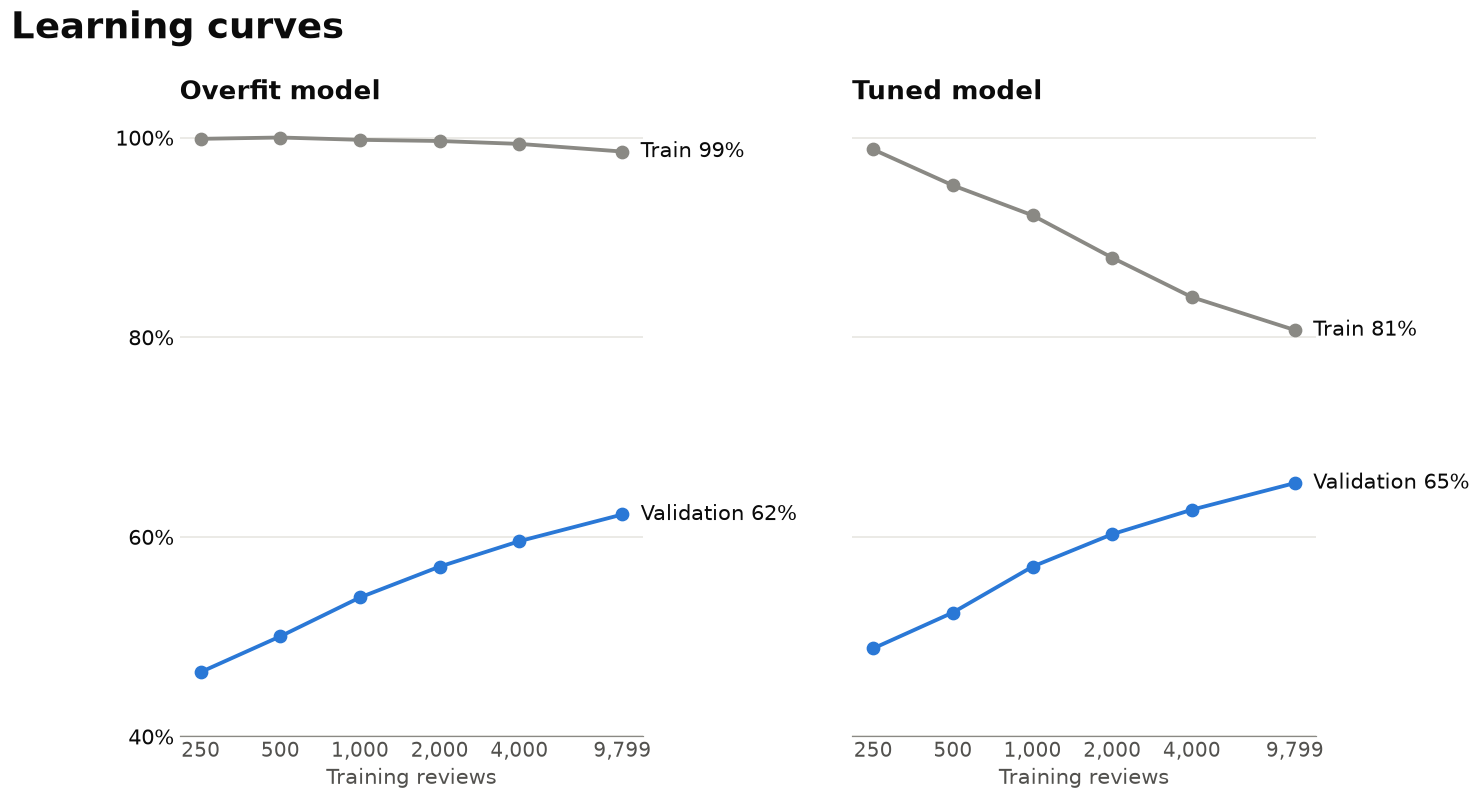

In [38]:
with plt.rc_context(SLIDE_RC):
    fig, axes = plt.subplots(1, 2, sharey=True, gridspec_kw={"wspace": 0.45})
    for ax, lc, title in [(axes[0], lc_overfit, "Overfit model"), (axes[1], lc_tuned, "Tuned model")]:
        x = lc.index.to_numpy()
        line_pair(ax, x, lc["train_acc"].to_numpy(), lc["val_acc"].to_numpy(), logx=True)
        ax.set_xticks(SIZES, [f"{n:,}" for n in SIZES])
        ax.minorticks_off()
        ax.set_title(title)
        ax.set_xlabel("Training reviews")
    slide_title(fig, "Learning curves")
    fig.subplots_adjust(top=0.86)
    save_slide(fig, "F_learning_curves")
    plt.show()

### Slide G: regularization closes the gap

saved figures/schachner/G_regularization.png


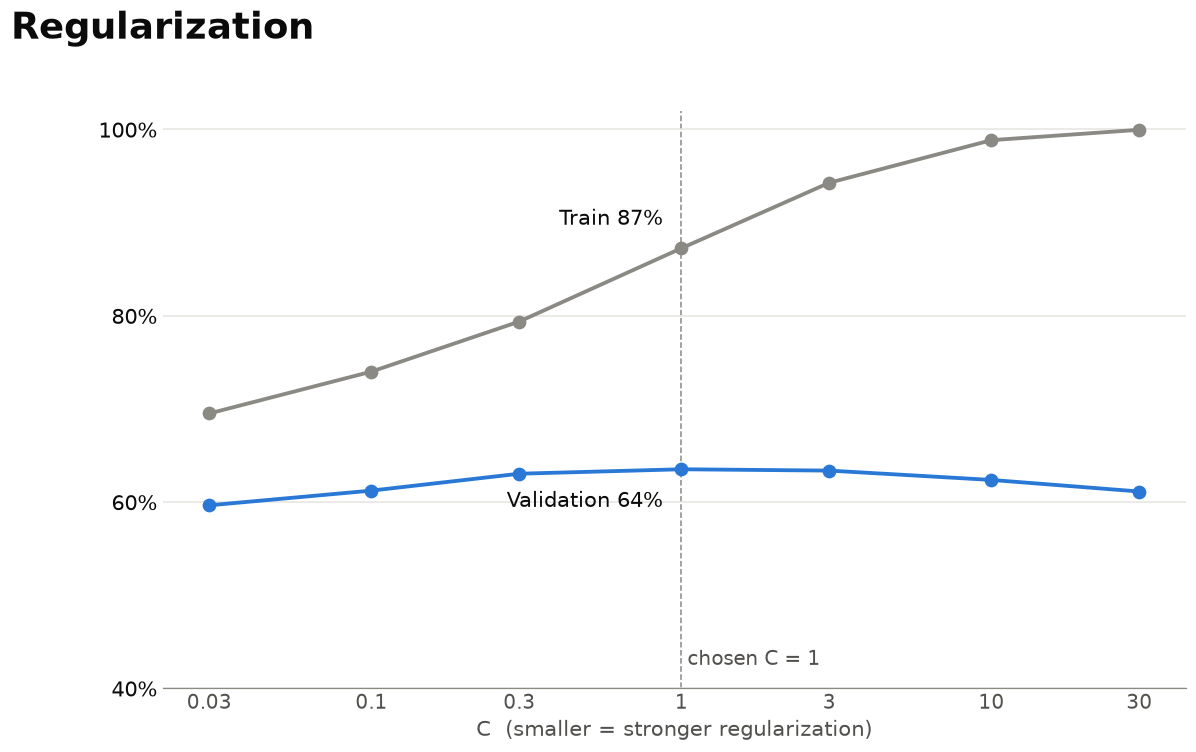

In [39]:
cs = c_sweep[c_sweep["class_weight"] == ("balanced" if TUNED["class_weight"] else "none")]
with plt.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(12, 7))
    chosen = int(np.flatnonzero(cs["C"].to_numpy() == TUNED["C"])[0])
    line_pair(ax, cs["C"].to_numpy(), cs["train_acc"].to_numpy(), cs["val_acc"].to_numpy(), logx=True,
              label_idx=chosen)
    ax.set_xticks(C_GRID, [f"{c:g}" for c in C_GRID])
    ax.minorticks_off()
    ax.axvline(TUNED["C"], color=INK_3, lw=1, ls="--", zorder=0)
    ax.text(TUNED["C"], 0.42, f" chosen C = {TUNED['C']:g}", ha="left", va="bottom", fontsize=13, color=INK_2)
    ax.set_xlabel("C  (smaller = stronger regularization)")
    slide_title(fig, "Regularization")
    fig.subplots_adjust(top=0.86)
    save_slide(fig, "G_regularization")
    plt.show()

### Slide H: before and after

saved figures/schachner/H_before_after.png


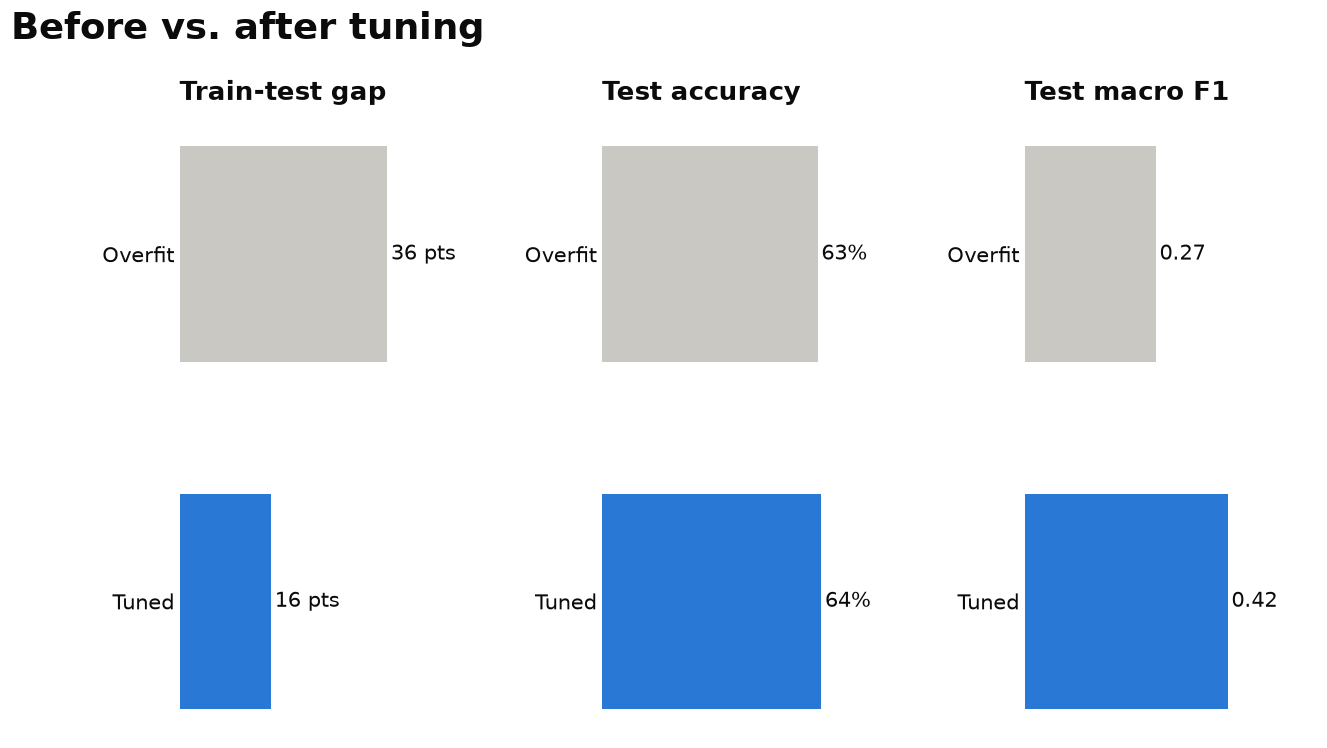

In [40]:
ba = final.loc[["Overfit model (Part 2)", "Tuned model, refit on train + validation"]]
names = ["Overfit", "Tuned"]
colors = [NEUTRAL, HILITE]
with plt.rc_context(SLIDE_RC):
    fig, axes = plt.subplots(1, 3, gridspec_kw={"wspace": 0.45})
    hbar(axes[0], names, (ba["gap"] * 100).to_numpy(), colors, fmt="{:.0f} pts", xmax=50)
    axes[0].set_title("Train-test gap")
    hbar(axes[1], names, ba["test_acc"].to_numpy(), colors, xmax=0.85)
    axes[1].set_title("Test accuracy")
    hbar(axes[2], names, ba["test_F1"].to_numpy(), colors, fmt="{:.2f}", xmax=0.6)
    axes[2].set_title("Test macro F1")
    slide_title(fig, "Before vs. after tuning")
    fig.subplots_adjust(top=0.86)
    save_slide(fig, "H_before_after")
    plt.show()

### Slide C: final model vs. baselines (test set)
The tuned Schachner model (refit on train + validation) next to the Part 2 baselines, all on the same test reviews.

saved figures/schachner/C_country_model_vs_baselines.png


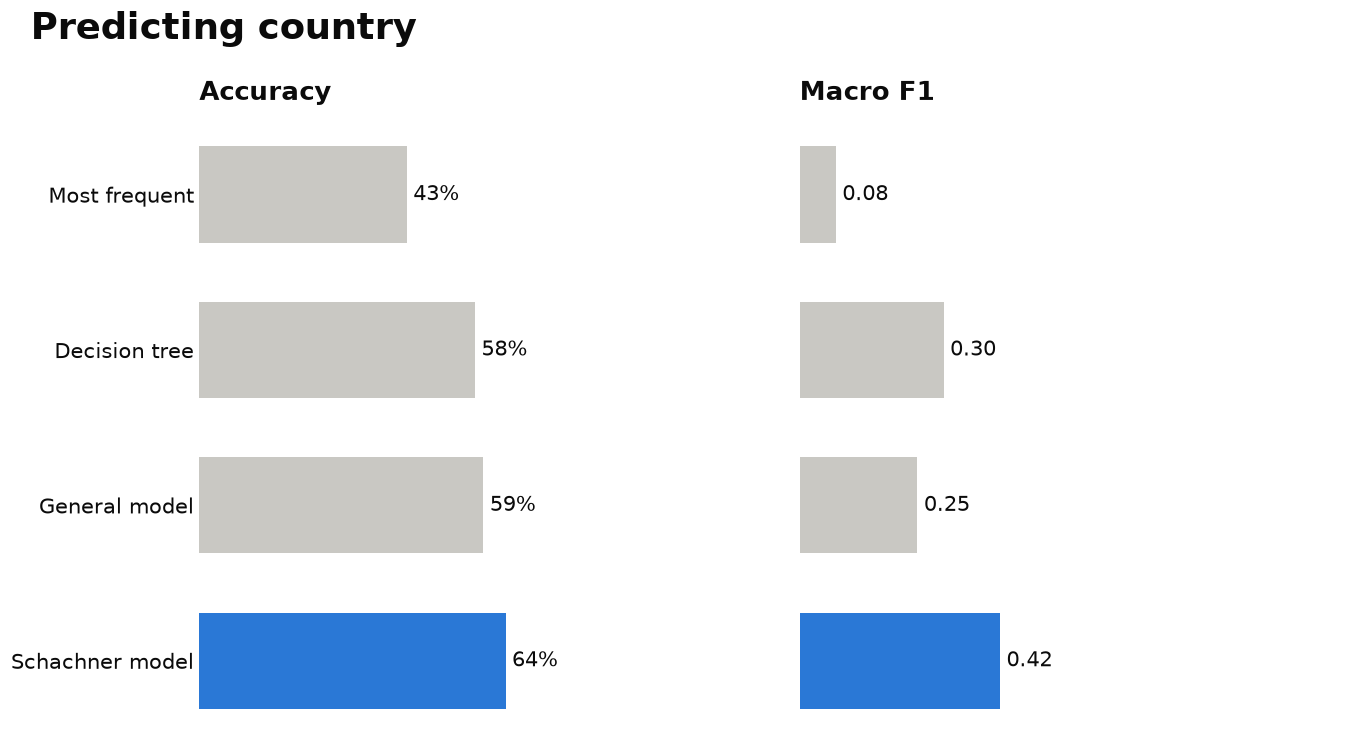

,accuracy,macro_F1
Most frequent,0.434,0.076
Decision tree,0.576,0.301
General model,0.594,0.246
Schachner model,0.640,0.419


In [41]:
FINAL = "Tuned model, refit on train + validation"
tuned_row = final.loc[FINAL]
base = test_results.loc["country"]
slide_c = pd.DataFrame({
    "Most frequent": base.loc["Most frequent (dummy)", ["accuracy", "macro_F1"]].to_numpy(),
    "Decision tree": base.loc["Decision tree", ["accuracy", "macro_F1"]].to_numpy(),
    "General model": base.loc["General model (all tasters)", ["accuracy", "macro_F1"]].to_numpy(),
    "Schachner model": [tuned_row["test_acc"], tuned_row["test_F1"]],
}, index=["accuracy", "macro_F1"]).T
colors_c = [NEUTRAL, NEUTRAL, NEUTRAL, HILITE]

with plt.rc_context(SLIDE_RC):
    fig, (ax1, ax2) = plt.subplots(1, 2, sharey=True, gridspec_kw={"wspace": 0.12})
    hbar(ax1, slide_c.index.tolist(), slide_c["accuracy"].to_numpy(), colors_c, xmax=1.12)
    ax1.set_title("Accuracy")
    hbar(ax2, slide_c.index.tolist(), slide_c["macro_F1"].to_numpy(), colors_c, fmt="{:.2f}", xmax=1.12)
    ax2.set_title("Macro F1")
    ax2.tick_params(axis="y", labelleft=False)
    slide_title(fig, "Predicting country")
    fig.subplots_adjust(top=0.86)
    save_slide(fig, "C_country_model_vs_baselines")
    plt.show()
slide_c.round(3)

### Slide E: where the final model goes wrong (test set)

saved figures/schachner/E_country_confusion.png


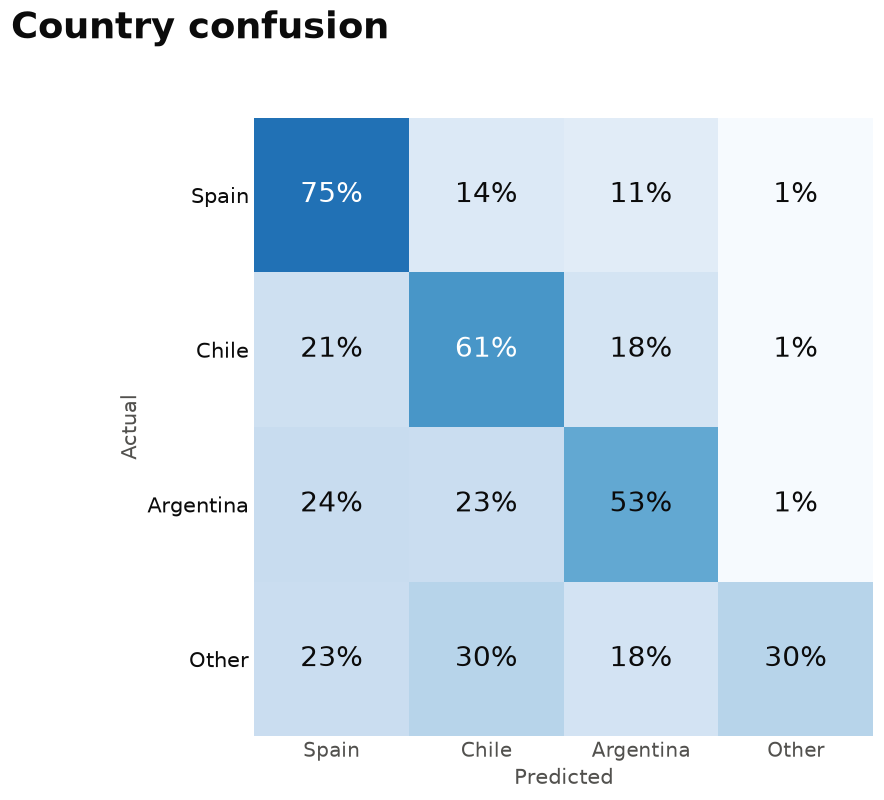

,Spain,Chile,Argentina,Other
Spain,680,123,100,7
Chile,128,371,110,4
Argentina,128,121,280,3
Other,10,13,8,13


In [42]:
vec, clf = final_models[FINAL]
y_final = cv_test["country"].to_numpy()
pred_final = clf.predict(vec.transform(cv_test["description"]))
group = lambda a: np.where(np.isin(a, MAIN), a, "Other")
labels = MAIN + ["Other"]
cm = confusion_matrix(group(y_final), group(pred_final), labels=labels)
share = cm / cm.sum(axis=1, keepdims=True)

with plt.rc_context(SLIDE_RC):
    fig, ax = plt.subplots(figsize=(10, 7.5))
    ax.imshow(share, cmap="Blues", vmin=0, vmax=1)
    for i, j in np.ndindex(cm.shape):
        ax.text(j, i, f"{share[i, j]:.0%}", ha="center", va="center", fontsize=18,
                color="white" if share[i, j] > 0.55 else INK)
    ax.set_xticks(range(4), labels)
    ax.set_yticks(range(4), labels)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("Actual")
    ax.tick_params(length=0)
    for s in ax.spines.values():
        s.set_visible(False)
    slide_title(fig, "Country confusion")
    fig.subplots_adjust(top=0.86)
    save_slide(fig, "E_country_confusion")
    plt.show()
pd.DataFrame(cm, index=labels, columns=labels)

## Takeaways

**1. Schachner and the country are nearly the same thing in this data.**
Schachner wrote 99% of Spain's, 97% of Chile's and 100% of Argentina's training reviews. Those three countries make up 97% of Schachner's 9,838 reviews. On the full dataset, a model separating these countries can't be distinguished from a model that recognizes Schachner's writing, so a within-taster comparison is the only way to separate the two.

**2. Scores, prices and review length barely change by country.**
- Median points are 87 for Spain, 86 for Chile and 87 for Argentina.
- The median review is 42 words in all three.
- Price predicts points about equally in each country: the slopes are 3.0 (Spain), 3.2 (Chile) and 3.6 (Argentina) points per log-dollar.
- Schachner doesn't score one country more harshly. The differences are in *what* gets said, not how much or how generously.

**3. Grape variety carries much of the country signal.**
Malbec is 40% of Argentina's reviews, Tempranillo 22% of Spain's and Carmenère 12% of Chile's. Only five varieties appear above 2% in more than one country: Malbec, Red Blend, Cabernet Sauvignon, Chardonnay and Pinot Noir. Without a careful setup, "predict the country" is largely "predict the grape".

**4. With place and grape names removed, each country still has its own vocabulary:**
- **Chile:** green and herbal (*olive, herbal, green, bell pepper, vegetal, asparagus, eucalyptus, nettle*) plus climate words (*coastal, cool, climate*). This fits Chile's cooler, coastal-influenced growing areas.
- **Argentina:** riper and heavier (*blackberry, blueberry, jammy, extracted, sweet, heavy, chocolate*). *Lychee* and *exotic* come from Torrontés white wines.
- **Spain:** sparkling-wine and older-wine words (*yeasty, leesy, bready, brut* from Cava; *mature, raisin, dusty*) and white stone fruit (*nectarine, peach, apple, stony*).

**5. With both taster and grape held fixed, most of the difference disappears.**
- **Cabernet Sauvignon, Chile (509 reviews) vs. Argentina (352):** only *olive* clearly leans Chilean (z ≈ 3.4). Every other word has |z| < 2, which is within noise.
- **Malbec, Argentina (991) vs. Chile (87):** no word reaches |z| > 1.5, though the Chilean sample is small.

So the country vocabulary in point 4 mostly reflects *which grapes* each country makes, not how Schachner describes the same grape from different places.

**6. A model can only partly recover country from Schachner's text.**

| Model (80/20 split inside Schachner's reviews) | Accuracy | Macro F1 |
|---|---|---|
| Always guess Spain | 44.3% | — |
| All words | 64.9% | 0.633 |
| Place and grape names removed | 53.4% | 0.521 |

- Even with grape names allowed, the model reaches only about 65%. Only 24% of Argentine reviews actually say "malbec", so the giveaway words are often missing.
- Removing names takes away about 11 points. Roughly **9 points above guessing** is the origin signal left once both taster and names are removed.
- Argentina is the hardest country: after removal, 32% of Argentine reviews are predicted as Spain.
- Changing the regularization strength (C from 0.3 to 10) moves accuracy by only about 2 points, so the ceiling comes from the data, not the model settings.

**7. Who Schachner is (slides A and B).** Schachner is the #2 taster by volume (9,838 training reviews, behind Voss) and reviews mostly everyday wines: the median bottle is $17 vs $27 for other tasters, and 59% are under $20 vs 29%. Median score is 87 vs 89. This is a value-wine reviewer for Spain and South America.

**8. Model comparison on the shared test split (sections 10-11, slide D).** These use the same setup as the Voss notebook plus the general all-tasters model, scored on Schachner's 2,108 test reviews:

| Test accuracy | Country (8 classes) | Province (29) | Region (45) |
|---|---|---|---|
| Most frequent (dummy) | 43.4% | 27.1% | 24.2% |
| Decision tree | 57.6% | 36.1% | 36.4% |
| General model (all tasters) | 59.4% | 40.6% | 40.9% |
| **Logistic regression (Schachner only)** | **62.9%** | **44.8%** | **42.7%** |
| Logistic regression, names removed | 53.7% | — | — |

- The Schachner-only logistic regression is best for all three targets: **+19.5 points** over the dummy for country, and 3.5 points better than the general model. This matches the Iijima result (single-taster model slightly beats the general model).
- **Macro F1 is low for every model (country 0.26 for the Schachner model)** because 5 of the 8 country classes have only a handful of test reviews and the model almost never predicts them. The decision tree has a slightly higher country macro F1 (0.30) for the same reason: it guesses small countries more often. A balanced-class model would trade some accuracy for better macro F1.
- Every model overfits: logistic regression is 99-100% accurate on training data vs 42-63% on validation. That's the same pattern as Voss and Krebiehl.
- **Untuned model (Part 2): Spain is easiest (80% correct). Argentina is hardest (45%), and is mistaken for Spain 31% of the time.** Reviews from Schachner's smaller countries (Uruguay, Italy, US and others) are almost never recognized: 5% correct. The tuned model's matrix is in section 9 below.

**9. Fixing the overfitting (Part 3, slides F-H).** The Part 2 model is 98.6% accurate on training data but 62.2% on validation: a 36-point gap, so high variance. Pulling each lever on validation:

| Lever | What happened |
|---|---|
| **More data** (learning curve) | Validation rises steadily, 46% → 62%, from 250 to 9,799 reviews and hasn't leveled off. More Schachner data would help, but none exists. |
| **Regularization** (smaller C) | C=10 → 1 shrinks the gap a lot with no loss in validation accuracy. Very small C (0.03) underfits. |
| **Balanced class weights** | Validation macro F1 goes from about 0.27 to 0.40, because the model starts predicting the small countries. |
| **Less capacity** (single words, 5k vocabulary) | Better than 1-2 word phrases: 65.3% vs 62.3% validation. The phrases mostly added variance. |
| **Decision tree depth** | Best around depth 20-30 (59% validation). Unlimited depth overfits (55%). |
| **Borrow other tasters' data** | Doesn't help: other tasters wrote only 153 reviews of Spain, Chile and Argentina. Adding their 47.9k US and Italy reviews *lowers* validation (65.4% → 64.1%) and macro F1 (0.44 → 0.38). |

**Chosen model** (best validation macro F1, with accuracy within 1 point of the best): single words, 5,000-word vocabulary, C=1, balanced classes. Refit on train + validation, then scored once on test:

| | Train-test gap | Test accuracy | Test macro F1 |
|---|---|---|---|
| Overfit model (Part 2 settings) | 36 pts | 62.9% | 0.27 |
| **Tuned model** | **16 pts** | **64.0%** | **0.42** |

- **Final model vs. baselines (slide C):** 64.0% test accuracy, against 43.4% for always guessing Spain, 57.6% for the decision tree and 59.4% for the general all-tasters model. Its macro F1 is 0.42, the best of all models (the next best is the decision tree at 0.30).
- **Final model's confusion matrix (slide E), share correct:** Spain 75%, Chile 61%, Argentina 53%, smaller countries 30%. Compared with the untuned model, balanced class weights trade some Spain accuracy (80% → 75%) for big gains on the others (smaller countries 5% → 30%). Argentina is still the hardest, confused with Spain (24%) and Chile (23%) about equally.
- The gap is less than half as big, and macro F1 rises by more than half. Accuracy only goes up about 1 point: the tuned model mainly gets the small countries right more often, rather than getting more reviews right overall.
- About 16 points of gap remain, and the learning curve is still rising, so the remaining error is mostly **not enough data**. With no more Schachner data available, that's the ceiling for a single-taster model.
- The overfit model's macro F1 here (0.27) is slightly different from Part 2's (0.26) because the vocabulary is built only from reviews in the kept countries. Accuracy is identical.

**What this means for the project:** the 85.8% country accuracy on the full data overstates the real origin signal. With the taster held fixed, country is only modestly predictable from the text. The remaining signal comes mainly from grape mix, plus a smaller real stylistic difference (Chile's "green" profile is the clearest). To confirm the pattern, repeat this analysis for another multi-country taster, such as Czerwinski or Voss.
